In [1]:
# =====================================================
# LINEAR REGRESSION - STEP 1
# Load and Verify Reliance Stock Dataset
# =====================================================

import os
import numpy as np
import pandas as pd

# 1. Define file path
project_path = (
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
)

data_path = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "Reliance_Prepared_Data_2017_2026.csv"
)

# 2. Check whether the file exists
if not os.path.exists(data_path):
    raise FileNotFoundError(
        f"Dataset not found at:\n{data_path}"
    )

print("Dataset file found successfully!")

# 3. Load dataset
df = pd.read_csv(data_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

# 4. Display first five rows
print("\nFirst five rows:")
display(df.head())

# 5. Display last five rows
print("\nLast five rows:")
display(df.tail())

# 6. Check column names
print("\nColumn names:")
print(df.columns.tolist())

# 7. Check data types
print("\nData types:")
print(df.dtypes)

# 8. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 9. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 10. Check duplicate dates, if Date exists
if "Date" in df.columns:
    dates = pd.to_datetime(df["Date"], errors="coerce")

    print("Invalid dates:", dates.isna().sum())
    print(
        "Duplicate dates:",
        dates.duplicated().sum()
    )

    print(
        "Date range:",
        dates.min(),
        "to",
        dates.max()
    )
else:
    print("WARNING: Date column is missing.")

# 11. Check infinite numerical values
numeric_df = df.select_dtypes(include=[np.number])

print(
    "\nInfinite values in numerical columns:"
)
print(
    pd.Series(
        np.isinf(numeric_df).sum(),
        index=numeric_df.columns
    )
)

# 12. Check required columns
required_columns = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Next_Day_Close"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("\nRequired-column verification:")
if not missing_columns:
    print("All required columns are present.")
else:
    print("Missing columns:", missing_columns)

print("\nStep 1 verification completed.")


Dataset file found successfully!

Dataset loaded successfully!
Dataset shape: (2400, 7)

First five rows:


,Date,Open,High,Low,Close,Volume,Next_Day_Close
0,2017-01-02,247.784164,249.155670,245.121170,248.035614,7097888,249.018509
1,2017-01-03,249.121384,250.755753,247.121277,249.018509,6434204,243.932541
2,2017-01-04,249.818558,249.841415,243.281082,243.932541,10392483,246.275513
3,2017-01-05,244.812592,246.846970,244.298279,246.275513,8734164,245.715485
4,2017-01-06,245.544052,248.012756,245.292603,245.715485,7845839,246.344086



Last five rows:


,Date,Open,High,Low,Close,Volume,Next_Day_Close
2395,2026-09-10,1278.500000,1285.300049,1266.300049,1274.000000,9296079,1257.500000
2396,2026-09-11,1267.000000,1267.400024,1253.000000,1257.500000,8777736,1235.300049
2397,2026-09-15,1252.500000,1259.400024,1235.300049,1235.300049,13754376,1240.000000
2398,2026-09-16,1243.000000,1255.000000,1240.000000,1240.000000,10023997,1243.900024
2399,2026-09-17,1244.800049,1253.400024,1238.500000,1243.900024,7752895,1226.400024



Column names:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Next_Day_Close']

Data types:
Date                  str
Open              float64
High              float64
Low               float64
Close             float64
Volume              int64
Next_Day_Close    float64
dtype: object

Missing values in each column:
Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
Next_Day_Close    0
dtype: int64

Duplicate rows: 0
Invalid dates: 0
Duplicate dates: 0
Date range: 2017-01-02 00:00:00 to 2026-09-17 00:00:00

Infinite values in numerical columns:
Open              0
High              0
Low               0
Close             0
Volume            0
Next_Day_Close    0
dtype: int64

Required-column verification:
All required columns are present.

Step 1 verification completed.


In [2]:
# =====================================================
# LINEAR REGRESSION - STEP 2
# Prepare Features (X) and Target (y)
# =====================================================

import pandas as pd

# 1. Define input features
feature_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

# 2. Define target variable
target_column = "Next_Day_Close"

# 3. Verify required columns
required_columns = feature_columns + [target_column]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# 4. Create feature matrix and target vector
X = df[feature_columns].copy()
y = df[target_column].copy()

# 5. Display the results
print("FEATURES AND TARGET PREPARED")
print("=" * 45)

print("\nInput features (X):")
print(feature_columns)

print("\nTarget variable (y):")
print(target_column)

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFirst five feature rows:")
display(X.head())

print("\nFirst five target values:")
display(y.head())

# 6. Verify data types
print("\nFeature data types:")
print(X.dtypes)

print("\nTarget data type:")
print(y.dtype)

# 7. Final verification
assert X.isnull().sum().sum() == 0
assert y.isnull().sum() == 0
assert X.shape[0] == y.shape[0]

print("\nStep 2 completed successfully!")


FEATURES AND TARGET PREPARED

Input features (X):
['Open', 'High', 'Low', 'Close', 'Volume']

Target variable (y):
Next_Day_Close

Feature matrix shape: (2400, 5)
Target vector shape: (2400,)

First five feature rows:


,Open,High,Low,Close,Volume
0,247.784164,249.155670,245.121170,248.035614,7097888
1,249.121384,250.755753,247.121277,249.018509,6434204
2,249.818558,249.841415,243.281082,243.932541,10392483
3,244.812592,246.846970,244.298279,246.275513,8734164
4,245.544052,248.012756,245.292603,245.715485,7845839



First five target values:


0    249.018509
1    243.932541
2    246.275513
3    245.715485
4    246.344086
Name: Next_Day_Close, dtype: float64


Feature data types:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

Target data type:
float64

Step 2 completed successfully!


In [3]:
# =====================================================
# LINEAR REGRESSION - STEP 3
# Chronological Train-Test Split (80:20)
# =====================================================

# 1. Calculate the split index
split_index = int(len(df) * 0.80)

# 2. Exclude the boundary row to avoid target leakage
train_end = split_index - 1

# 3. Create training and testing datasets
X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_test = X.iloc[split_index:].copy()
y_test = y.iloc[split_index:].copy()

# 4. Extract corresponding dates
train_dates = df["Date"].iloc[:train_end]
test_dates = df["Date"].iloc[split_index:]

# 5. Display split information
print("TRAIN-TEST SPLIT SUMMARY")
print("=" * 50)

print("Total dataset rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining date range:")
print(train_dates.min(), "to", train_dates.max())

print("\nTesting date range:")
print(test_dates.min(), "to", test_dates.max())

print("\nTraining feature shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("\nTesting feature shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

# 6. Verify split correctness
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert train_dates.max() < test_dates.min()

print("\nTrain-test split verified successfully!")


TRAIN-TEST SPLIT SUMMARY
Total dataset rows: 2400
Training rows: 1919
Testing rows: 480

Training date range:
2017-01-02 to 2024-10-09

Testing date range:
2024-10-11 to 2026-09-17

Training feature shape: (1919, 5)
Training target shape: (1919,)

Testing feature shape: (480, 5)
Testing target shape: (480,)

Train-test split verified successfully!


STEP 4: LINEAR REGRESSION MODEL TRAINING AND EVALUATION

1. Output directory created/verified.
   Results will be saved in: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression

2. Linear Regression model initialized.
   The model will learn the relationship between
   Open, High, Low, Close, Volume and Next_Day_Close.

3. Model training completed successfully.
   Training rows used: 1919
   Input features used: ['Open', 'High', 'Low', 'Close', 'Volume']

4. Predictions generated successfully.
   Training predictions: 1919
   Testing predictions: 480

5. Evaluation metrics configured:
   MAE      : Average absolute prediction error.
   RMSE     : Error metric that penalizes large errors.
   R-squared: Measures how well the model explains variation.
   MAPE     : Mean absolute percentage error.
   Accuracy : 100 - MAPE, a custom regression indicator.

6. MODEL EVALUATION RESULTS


,Dataset,MAE,RMSE,R2,MAPE_Percentage,Prediction_Accuracy_Percentage
0,Training,11.4208,16.3447,0.9980,1.3875,98.6125
1,Testing,14.6925,19.5739,0.9581,1.0854,98.9146



7. Evaluation metrics saved successfully.
   File: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Evaluation_Metrics.csv

8. Test predictions saved successfully.
   File: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Test_Predictions.csv


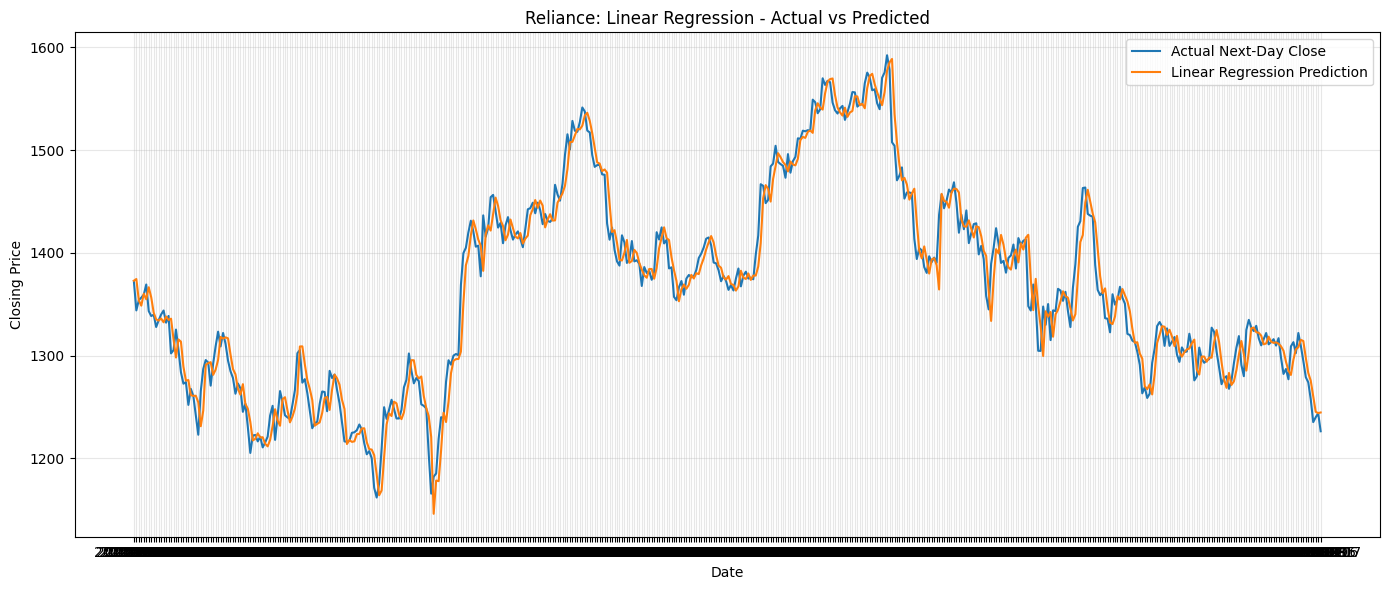


9. Actual vs Predicted graph generated and saved.
   File: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Actual_vs_Predicted.png

STEP 4 COMPLETED SUCCESSFULLY
What happened in this step?
- The Linear Regression model was trained on historical data.
- The model predicted Next_Day_Close for training and testing data.
- Training and testing performance were evaluated.
- MAE, RMSE, R-squared, MAPE and prediction accuracy were calculated.
- Evaluation metrics, test predictions and the graph were saved.

Important interpretation:
- Lower MAE, RMSE and MAPE generally indicate smaller errors.
- Higher R-squared can indicate a better fit, but it can be negative.
- Prediction accuracy here is calculated as 100 - MAPE.
- This is a custom regression indicator, not classification accuracy.
- A negative prediction accuracy is possible if MAPE exceeds 100%.

All Step 4 outputs have been generated.


In [4]:
# =====================================================
# LINEAR REGRESSION - STEP 4
# Model Training and Evaluation
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# 1. Create output directory
output_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "linear_regression"
)

os.makedirs(output_dir, exist_ok=True)

print("=" * 65)
print("STEP 4: LINEAR REGRESSION MODEL TRAINING AND EVALUATION")
print("=" * 65)

print("\n1. Output directory created/verified.")
print("   Results will be saved in:", output_dir)

# 2. Initialize Linear Regression
linear_model = LinearRegression()

print("\n2. Linear Regression model initialized.")
print("   The model will learn the relationship between")
print("   Open, High, Low, Close, Volume and Next_Day_Close.")

# 3. Train the model
linear_model.fit(X_train, y_train)

print("\n3. Model training completed successfully.")
print("   Training rows used:", len(X_train))
print("   Input features used:", list(X_train.columns))

# 4. Generate predictions
y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)

print("\n4. Predictions generated successfully.")
print("   Training predictions:", len(y_train_pred))
print("   Testing predictions:", len(y_test_pred))

# 5. Define evaluation function
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    # MAPE is undefined when actual values are zero.
    actual_array = np.asarray(actual, dtype=float)
    predicted_array = np.asarray(predicted, dtype=float)

    nonzero_mask = actual_array != 0

    if nonzero_mask.any():
        mape = mean_absolute_percentage_error(
            actual_array[nonzero_mask],
            predicted_array[nonzero_mask]
        ) * 100

        prediction_accuracy = 100 - mape
    else:
        mape = np.nan
        prediction_accuracy = np.nan

    return mae, rmse, r2, mape, prediction_accuracy

print("\n5. Evaluation metrics configured:")
print("   MAE      : Average absolute prediction error.")
print("   RMSE     : Error metric that penalizes large errors.")
print("   R-squared: Measures how well the model explains variation.")
print("   MAPE     : Mean absolute percentage error.")
print("   Accuracy : 100 - MAPE, a custom regression indicator.")

# 6. Evaluate training and testing performance
train_mae, train_rmse, train_r2, train_mape, train_accuracy = (
    evaluate_model(y_train, y_train_pred)
)

test_mae, test_rmse, test_r2, test_mape, test_accuracy = (
    evaluate_model(y_test, y_test_pred)
)

# 7. Create metrics table
metrics_df = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse],
    "R2": [train_r2, test_r2],
    "MAPE_Percentage": [train_mape, test_mape],
    "Prediction_Accuracy_Percentage": [
        train_accuracy,
        test_accuracy
    ]
})

print("\n6. MODEL EVALUATION RESULTS")
print("=" * 80)
display(metrics_df.round(4))

# 8. Save evaluation metrics
metrics_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Evaluation_Metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

print("\n7. Evaluation metrics saved successfully.")
print("   File:", metrics_path)

# 9. Save test predictions
predictions_df = pd.DataFrame({
    "Date": df["Date"].iloc[split_index:].values,
    "Actual_Next_Day_Close": y_test.values,
    "Predicted_Next_Day_Close": y_test_pred
})

predictions_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Test_Predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

print("\n8. Test predictions saved successfully.")
print("   File:", predictions_path)

# 10. Plot actual vs predicted values
plt.figure(figsize=(14, 6))

plt.plot(
    predictions_df["Date"],
    predictions_df["Actual_Next_Day_Close"],
    label="Actual Next-Day Close"
)

plt.plot(
    predictions_df["Date"],
    predictions_df["Predicted_Next_Day_Close"],
    label="Linear Regression Prediction"
)

plt.title(
    "Reliance: Linear Regression - Actual vs Predicted"
)
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

graph_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Actual_vs_Predicted.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n9. Actual vs Predicted graph generated and saved.")
print("   File:", graph_path)

# 11. Final program summary
print("\n" + "=" * 65)
print("STEP 4 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("What happened in this step?")
print("- The Linear Regression model was trained on historical data.")
print("- The model predicted Next_Day_Close for training and testing data.")
print("- Training and testing performance were evaluated.")
print("- MAE, RMSE, R-squared, MAPE and prediction accuracy were calculated.")
print("- Evaluation metrics, test predictions and the graph were saved.")

print("\nImportant interpretation:")
print("- Lower MAE, RMSE and MAPE generally indicate smaller errors.")
print("- Higher R-squared can indicate a better fit, but it can be negative.")
print("- Prediction accuracy here is calculated as 100 - MAPE.")
print("- This is a custom regression indicator, not classification accuracy.")
print("- A negative prediction accuracy is possible if MAPE exceeds 100%.")

print("\nAll Step 4 outputs have been generated.")

STEP 5: OVERFITTING AND UNDERFITTING DIAGNOSIS

1. PURPOSE OF THIS STEP
- Comparing training and testing performance.
- Checking whether the model generalizes to unseen data.
- Identifying possible signs of overfitting or underfitting.

2. TRAINING VS TESTING PERFORMANCE
---------------------------------------------------------------------------


,Metric,Training,Testing,Absolute_Gap
0,MAE,11.4208,14.6925,3.2716
1,RMSE,16.3447,19.5739,3.2292
2,R2,0.9980,0.9581,0.0399
3,Prediction_Accuracy_Percentage,98.6125,98.9146,0.3020



3. METRIC GAP INTERPRETATION
---------------------------------------------------------------------------
MAE gap: 3.2716
Meaning: Difference between training and testing absolute errors.

RMSE gap: 3.2292
Meaning: Difference between training and testing squared-error-based metrics.

R-squared gap: 0.0399
Meaning: Difference between training and testing goodness of fit.

Prediction Accuracy gap: 0.3020%
Meaning: Difference between training and testing custom regression accuracy.

4. MODEL DIAGNOSIS
---------------------------------------------------------------------------
Observation: Testing performance is worse than training performance.
Interpretation: This may indicate overfitting or a time-period difference.
Further validation is needed before confirming overfitting.

Important notes:
- Overfitting occurs when a model fits training data well but generalizes poorly.
- Underfitting occurs when a model fails to learn the underlying patterns adequately.
- Large gaps can indicate a ge

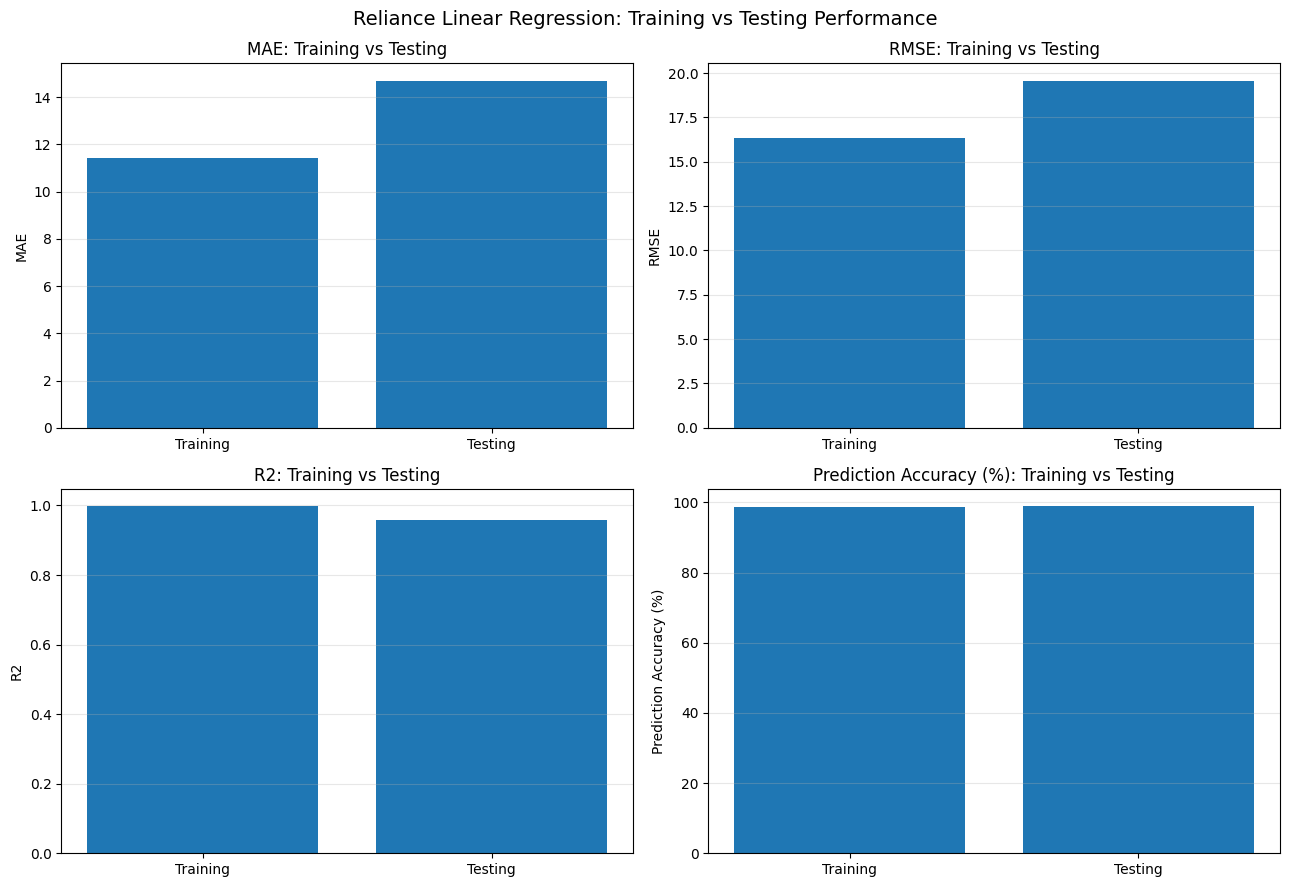


6. COMPARISON GRAPH SAVED
File: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Training_Testing_Comparison.png

STEP 5 COMPLETED SUCCESSFULLY
What happened in this step?
1. Training and testing evaluation metrics were compared.
2. Absolute gaps were calculated for MAE, RMSE, R2 and accuracy.
3. The results were examined for possible generalization problems.
4. The diagnosis table was saved as a CSV file.
5. A graph comparing training and testing metrics was generated.

Both output files are stored in:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression


In [5]:
# =====================================================
# LINEAR REGRESSION - STEP 5
# Overfitting and Underfitting Diagnosis
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create output directory
output_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "linear_regression"
)

os.makedirs(output_dir, exist_ok=True)

print("=" * 75)
print("STEP 5: OVERFITTING AND UNDERFITTING DIAGNOSIS")
print("=" * 75)

print("\n1. PURPOSE OF THIS STEP")
print("- Comparing training and testing performance.")
print("- Checking whether the model generalizes to unseen data.")
print("- Identifying possible signs of overfitting or underfitting.")

# 2. Calculate absolute gaps
mae_gap = abs(test_mae - train_mae)
rmse_gap = abs(test_rmse - train_rmse)
r2_gap = abs(train_r2 - test_r2)

# Prediction accuracy from Step 4: 100 - MAPE
train_accuracy = 100 - (
    mean_absolute_percentage_error(y_train, y_train_pred) * 100
)

test_accuracy = 100 - (
    mean_absolute_percentage_error(y_test, y_test_pred) * 100
)

accuracy_gap = abs(test_accuracy - train_accuracy)

# 3. Create diagnosis table
diagnosis_df = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2",
        "Prediction_Accuracy_Percentage"
    ],
    "Training": [
        train_mae,
        train_rmse,
        train_r2,
        train_accuracy
    ],
    "Testing": [
        test_mae,
        test_rmse,
        test_r2,
        test_accuracy
    ],
    "Absolute_Gap": [
        mae_gap,
        rmse_gap,
        r2_gap,
        accuracy_gap
    ]
})

print("\n2. TRAINING VS TESTING PERFORMANCE")
print("-" * 75)
display(diagnosis_df.round(4))

# 4. Explain the metric gaps
print("\n3. METRIC GAP INTERPRETATION")
print("-" * 75)

print(f"MAE gap: {mae_gap:.4f}")
print("Meaning: Difference between training and testing absolute errors.")

print(f"\nRMSE gap: {rmse_gap:.4f}")
print("Meaning: Difference between training and testing squared-error-based metrics.")

print(f"\nR-squared gap: {r2_gap:.4f}")
print("Meaning: Difference between training and testing goodness of fit.")

print(f"\nPrediction Accuracy gap: {accuracy_gap:.4f}%")
print("Meaning: Difference between training and testing custom regression accuracy.")

# 5. Diagnose possible overfitting or underfitting
print("\n4. MODEL DIAGNOSIS")
print("-" * 75)

if (
    test_mae > train_mae
    and test_rmse > train_rmse
    and train_r2 > test_r2
):
    print("Observation: Testing performance is worse than training performance.")
    print("Interpretation: This may indicate overfitting or a time-period difference.")
    print("Further validation is needed before confirming overfitting.")

elif (
    train_mae > test_mae
    and train_rmse > test_rmse
):
    print("Observation: Testing errors are lower than training errors.")
    print("Interpretation: The model performs better on the test period.")
    print("This does not automatically prove underfitting.")

else:
    print("Observation: The metrics show a mixed performance pattern.")
    print("Interpretation: No definite conclusion can be drawn from these gaps alone.")

print("\nImportant notes:")
print("- Overfitting occurs when a model fits training data well but generalizes poorly.")
print("- Underfitting occurs when a model fails to learn the underlying patterns adequately.")
print("- Large gaps can indicate a generalization problem, but there is no universal")
print("  threshold that proves overfitting.")
print("- Compare performance with a baseline and use time-series cross-validation.")
print("- Prediction Accuracy = 100 - MAPE (%); it is not standard classification accuracy.")
print("- Negative prediction accuracy is possible when MAPE exceeds 100%.")

# 6. Save diagnosis table
diagnosis_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Overfitting_Diagnosis.csv"
)

diagnosis_df.to_csv(diagnosis_path, index=False)

print("\n5. DIAGNOSIS TABLE SAVED")
print("File:", diagnosis_path)

# 7. Plot training vs testing metrics
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = [
    ("MAE", train_mae, test_mae),
    ("RMSE", train_rmse, test_rmse),
    ("R2", train_r2, test_r2),
    (
        "Prediction Accuracy (%)",
        train_accuracy,
        test_accuracy
    )
]

for ax, (name, train_value, test_value) in zip(
    axes.flat, metrics
):
    ax.bar(
        ["Training", "Testing"],
        [train_value, test_value]
    )

    ax.set_title(f"{name}: Training vs Testing")
    ax.set_ylabel(name)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Reliance Linear Regression: Training vs Testing Performance",
    fontsize=14
)

plt.tight_layout()

graph_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Training_Testing_Comparison.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n6. COMPARISON GRAPH SAVED")
print("File:", graph_path)

# 8. Final program summary
print("\n" + "=" * 75)
print("STEP 5 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("What happened in this step?")
print("1. Training and testing evaluation metrics were compared.")
print("2. Absolute gaps were calculated for MAE, RMSE, R2 and accuracy.")
print("3. The results were examined for possible generalization problems.")
print("4. The diagnosis table was saved as a CSV file.")
print("5. A graph comparing training and testing metrics was generated.")
print("\nBoth output files are stored in:")
print(output_dir)

STEP 6: DETAILED GENERALIZATION GAP ANALYSIS

PURPOSE
Investigate why testing performance is worse than training performance.
Check prediction errors and performance changes across the test period.

1. TRAINING VS TESTING METRICS
---------------------------------------------------------------------------


,Metric,Training,Testing,Testing_Minus_Training
0,MAE,11.4208,14.6925,3.2716
1,RMSE,16.3447,19.5739,3.2292
2,R2,0.9980,0.9581,-0.0399
3,MAPE_Percentage,1.3875,1.0854,-0.3020
4,Prediction_Accuracy_Percentage,98.6125,98.9146,0.3020



2. GENERALIZATION GAP
---------------------------------------------------------------------------
MAE gap (test - train): 3.2716
RMSE gap (test - train): 3.2292
R2 gap (train - test): 0.0399
Accuracy gap (train - test): -0.3020 percentage points

Finding: Testing errors are higher and testing R2 is lower.
This is evidence of a generalization gap.
It may reflect overfitting, changing market conditions,
or other differences between the training and testing periods.

3. TESTING ERROR ANALYSIS
---------------------------------------------------------------------------
Average absolute error: 14.6925
Largest absolute error: 81.1253
Average percentage error (%): 1.0854

First five test prediction errors:


C:\Users\Shilpi Chouhan\AppData\Local\Temp\ipykernel_19124\21625695.py:176: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(test_results_df.head().round(4))


,Date,Actual_Next_Day_Close,Predicted_Next_Day_Close,Absolute_Error,Percentage_Error
0,2024-10-11,1372.525,1372.9218,0.3968,0.0289
1,2024-10-14,1344.025,1374.5364,30.5114,2.2702
2,2024-10-15,1354.075,1353.7691,0.3058,0.0226
3,2024-10-16,1356.425,1348.6340,7.7911,0.5744
4,2024-10-17,1359.300,1360.2233,0.9232,0.0679



4. ERROR PATTERN ACROSS THE TEST PERIOD
---------------------------------------------------------------------------


,Test_Period,Number_of_Rows,Mean_Absolute_Error,Mean_Percentage_Error
0,Period 1,120,14.1882,1.1255
1,Period 2,120,14.3496,1.0344
2,Period 3,120,14.2193,0.9768
3,Period 4,120,16.0128,1.2050


Purpose: This comparison checks whether prediction errors
increase or decrease during different portions of the test period.
Changes may reflect volatility or changing market conditions.

5. ANALYSIS FILES SAVED
Metrics comparison: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Generalization_Gap.csv
Test errors: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Test_Error_Analysis.csv
Period analysis: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Period_Error_Analysis.csv


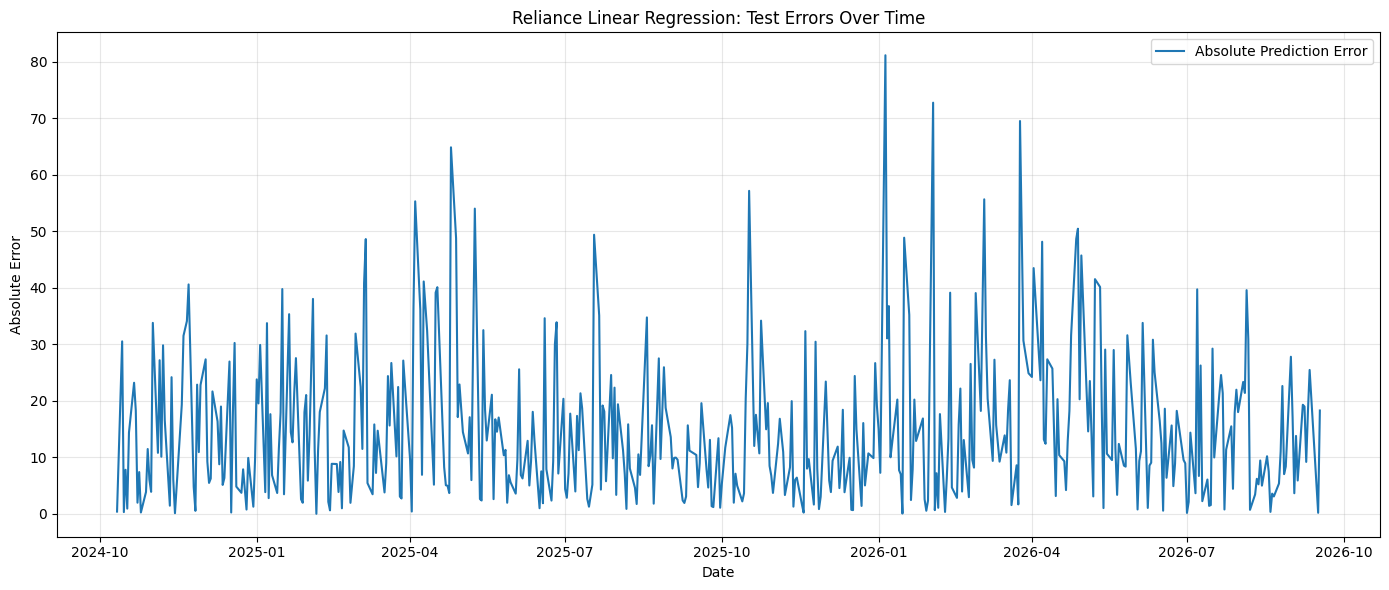


6. ERROR GRAPH SAVED
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Test_Errors_Over_Time.png

STEP 6 COMPLETED SUCCESSFULLY
What happened in this step?
1. Training and testing metrics were recalculated.
2. Generalization gaps were quantified.
3. Individual test prediction errors were analyzed.
4. Errors were compared across chronological test-period sections.
5. Three CSV reports and an error-over-time graph were saved.

CONCLUSION
A generalization gap can indicate that the model performs differently
on unseen data. This analysis alone cannot prove overfitting.
A chronological baseline and time-series cross-validation can
provide stronger evidence about model generalization.

All Step 6 outputs are stored in:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression


In [6]:
# =====================================================
# LINEAR REGRESSION - STEP 6
# Detailed Generalization Gap Analysis
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# 1. Create output directory
output_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "linear_regression"
)

os.makedirs(output_dir, exist_ok=True)

print("=" * 75)
print("STEP 6: DETAILED GENERALIZATION GAP ANALYSIS")
print("=" * 75)

print("\nPURPOSE")
print("Investigate why testing performance is worse than training performance.")
print("Check prediction errors and performance changes across the test period.")

# 2. Generate predictions if they are not already available
y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)

# 3. Calculate metrics consistently
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    nonzero_mask = actual != 0

    if nonzero_mask.any():
        mape = mean_absolute_percentage_error(
            actual[nonzero_mask],
            predicted[nonzero_mask]
        ) * 100

        prediction_accuracy = 100 - mape
    else:
        mape = np.nan
        prediction_accuracy = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_Percentage": mape,
        "Prediction_Accuracy_Percentage": prediction_accuracy
    }

train_metrics = calculate_metrics(y_train, y_train_pred)
test_metrics = calculate_metrics(y_test, y_test_pred)

# 4. Calculate generalization gaps
# Positive error gaps mean testing errors are higher.
# Positive R2 gap means training R2 is higher than testing R2.

mae_gap = test_metrics["MAE"] - train_metrics["MAE"]
rmse_gap = test_metrics["RMSE"] - train_metrics["RMSE"]
r2_gap = train_metrics["R2"] - test_metrics["R2"]

accuracy_gap = (
    train_metrics["Prediction_Accuracy_Percentage"]
    - test_metrics["Prediction_Accuracy_Percentage"]
)

# 5. Create comparison table
comparison_df = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2",
        "MAPE_Percentage",
        "Prediction_Accuracy_Percentage"
    ],
    "Training": [
        train_metrics["MAE"],
        train_metrics["RMSE"],
        train_metrics["R2"],
        train_metrics["MAPE_Percentage"],
        train_metrics["Prediction_Accuracy_Percentage"]
    ],
    "Testing": [
        test_metrics["MAE"],
        test_metrics["RMSE"],
        test_metrics["R2"],
        test_metrics["MAPE_Percentage"],
        test_metrics["Prediction_Accuracy_Percentage"]
    ]
})

comparison_df["Testing_Minus_Training"] = (
    comparison_df["Testing"] - comparison_df["Training"]
)

print("\n1. TRAINING VS TESTING METRICS")
print("-" * 75)
display(comparison_df.round(4))

# 6. Explain the generalization gap
print("\n2. GENERALIZATION GAP")
print("-" * 75)

print(f"MAE gap (test - train): {mae_gap:.4f}")
print(f"RMSE gap (test - train): {rmse_gap:.4f}")
print(f"R2 gap (train - test): {r2_gap:.4f}")
print(f"Accuracy gap (train - test): {accuracy_gap:.4f} percentage points")

if mae_gap > 0 and rmse_gap > 0 and r2_gap > 0:
    print("\nFinding: Testing errors are higher and testing R2 is lower.")
    print("This is evidence of a generalization gap.")
    print("It may reflect overfitting, changing market conditions,")
    print("or other differences between the training and testing periods.")
else:
    print("\nFinding: The metrics do not all show the same pattern.")
    print("Interpret the individual metrics before drawing conclusions.")

# 7. Examine test prediction errors over time
test_results_df = pd.DataFrame({
    "Date": pd.to_datetime(
        df["Date"].iloc[split_index:],
        errors="coerce"
    ).to_numpy(),
    "Actual_Next_Day_Close": np.asarray(y_test),
    "Predicted_Next_Day_Close": y_test_pred
})

test_results_df["Absolute_Error"] = abs(
    test_results_df["Actual_Next_Day_Close"]
    - test_results_df["Predicted_Next_Day_Close"]
)

test_results_df["Percentage_Error"] = np.where(
    test_results_df["Actual_Next_Day_Close"] != 0,
    test_results_df["Absolute_Error"]
    / abs(test_results_df["Actual_Next_Day_Close"]) * 100,
    np.nan
)

print("\n3. TESTING ERROR ANALYSIS")
print("-" * 75)

print("Average absolute error:", round(
    test_results_df["Absolute_Error"].mean(), 4
))

print("Largest absolute error:", round(
    test_results_df["Absolute_Error"].max(), 4
))

print("Average percentage error (%):", round(
    test_results_df["Percentage_Error"].mean(), 4
))

print("\nFirst five test prediction errors:")
display(test_results_df.head().round(4))

# 8. Analyze errors across chronological test-period sections
test_results_df = test_results_df.sort_values("Date").reset_index(drop=True)

test_results_df["Test_Period"] = pd.qcut(
    np.arange(len(test_results_df)),
    q=min(4, len(test_results_df)),
    labels=[
        f"Period {i + 1}"
        for i in range(min(4, len(test_results_df)))
    ],
    duplicates="drop"
)

period_analysis_df = (
    test_results_df.groupby("Test_Period", observed=True)
    .agg(
        Number_of_Rows=("Absolute_Error", "size"),
        Mean_Absolute_Error=("Absolute_Error", "mean"),
        Mean_Percentage_Error=("Percentage_Error", "mean")
    )
    .reset_index()
)

print("\n4. ERROR PATTERN ACROSS THE TEST PERIOD")
print("-" * 75)
display(period_analysis_df.round(4))

print("Purpose: This comparison checks whether prediction errors")
print("increase or decrease during different portions of the test period.")
print("Changes may reflect volatility or changing market conditions.")

# 9. Save analysis tables
comparison_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Generalization_Gap.csv"
)

errors_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Test_Error_Analysis.csv"
)

period_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Period_Error_Analysis.csv"
)

comparison_df.to_csv(comparison_path, index=False)
test_results_df.to_csv(errors_path, index=False)
period_analysis_df.to_csv(period_path, index=False)

print("\n5. ANALYSIS FILES SAVED")
print("Metrics comparison:", comparison_path)
print("Test errors:", errors_path)
print("Period analysis:", period_path)

# 10. Plot absolute prediction errors over time
plt.figure(figsize=(14, 6))

plt.plot(
    test_results_df["Date"],
    test_results_df["Absolute_Error"],
    label="Absolute Prediction Error"
)

plt.title("Reliance Linear Regression: Test Errors Over Time")
plt.xlabel("Date")
plt.ylabel("Absolute Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

error_graph_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Test_Errors_Over_Time.png"
)

plt.savefig(error_graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("\n6. ERROR GRAPH SAVED")
print(error_graph_path)

# 11. Final summary
print("\n" + "=" * 75)
print("STEP 6 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("What happened in this step?")
print("1. Training and testing metrics were recalculated.")
print("2. Generalization gaps were quantified.")
print("3. Individual test prediction errors were analyzed.")
print("4. Errors were compared across chronological test-period sections.")
print("5. Three CSV reports and an error-over-time graph were saved.")

print("\nCONCLUSION")
print("A generalization gap can indicate that the model performs differently")
print("on unseen data. This analysis alone cannot prove overfitting.")
print("A chronological baseline and time-series cross-validation can")
print("provide stronger evidence about model generalization.")

print("\nAll Step 6 outputs are stored in:")
print(output_dir)

STEP 7: BASELINE COMPARISON AND TIME-SERIES CROSS-VALIDATION

PURPOSE
1. Compare Linear Regression with a simple stock-price baseline.
2. Evaluate the model across multiple chronological validation folds.
3. Check whether the model performs consistently on unseen data.

1. CHRONOLOGICAL BASELINE COMPARISON
---------------------------------------------------------------------------

Test-set performance comparison:


,Model,MAE,RMSE,R2,MAPE_Percentage,Prediction_Accuracy_Percentage
0,Chronological Baseline,13.2601,17.5983,0.9662,0.9790,99.0210
1,Linear Regression,14.6925,19.5739,0.9581,1.0854,98.9146



BASELINE COMPARISON INTERPRETATION
---------------------------------------------------------------------------
MAE improvement: -1.4324
RMSE improvement: -1.9756
Finding: The baseline has lower MAE and RMSE.
Linear Regression does not outperform the baseline
on these error metrics.

Note: This baseline predicts tomorrow's Close using today's Close.
It is a benchmark, not a trained machine-learning model.

2. TIME-SERIES CROSS-VALIDATION
---------------------------------------------------------------------------

Fold 1 completed.
Training rows: 400
Validation rows: 400
Validation period: 2018-08-09 to 2020-03-31

Fold 2 completed.
Training rows: 800
Validation rows: 400
Validation period: 2020-04-01 to 2021-11-10

Fold 3 completed.
Training rows: 1200
Validation rows: 400
Validation period: 2021-11-11 to 2023-06-21

Fold 4 completed.
Training rows: 1600
Validation rows: 400
Validation period: 2023-06-22 to 2025-02-03

Fold 5 completed.
Training rows: 2000
Validation rows: 400
Validati

,Fold,Training_Rows,Validation_Rows,Training_Start,Training_End,Validation_Start,Validation_End,MAE,RMSE,R2,MAPE_Percentage,Prediction_Accuracy_Percentage
0,1,400,400,2017-01-02,2018-08-08,2018-08-09,2020-03-31,9.8119,13.4675,0.9604,1.7280,98.2720
1,2,800,400,2017-01-02,2020-03-31,2020-04-01,2021-11-10,14.4946,19.5077,0.9805,1.5925,98.4075
2,3,1200,400,2017-01-02,2021-11-10,2021-11-11,2023-06-21,15.0367,19.7834,0.8793,1.3121,98.6879
3,4,1600,400,2017-01-02,2023-06-21,2023-06-22,2025-02-03,13.9423,19.3577,0.9760,1.0316,98.9684
4,5,2000,400,2017-01-02,2025-02-03,2025-02-04,2026-09-17,14.7582,19.8256,0.9556,1.0770,98.9230



4. CROSS-VALIDATION SUMMARY
---------------------------------------------------------------------------


,Metric,Mean,Standard_Deviation
0,MAE,13.6087,2.1606
1,RMSE,18.3884,2.7577
2,R2,0.9503,0.0411
3,MAPE_Percentage,1.3482,0.3078
4,Prediction_Accuracy_Percentage,98.6518,0.3078



Interpretation:
- Mean MAE and RMSE summarize validation errors across folds.
- Standard deviation shows how much each metric varies across folds.
- Lower error variation can indicate more consistent performance.
- R2 may be negative when predictions are worse than a mean-value
  reference for a validation fold.
- Prediction Accuracy is 100 - MAPE, a custom regression indicator.


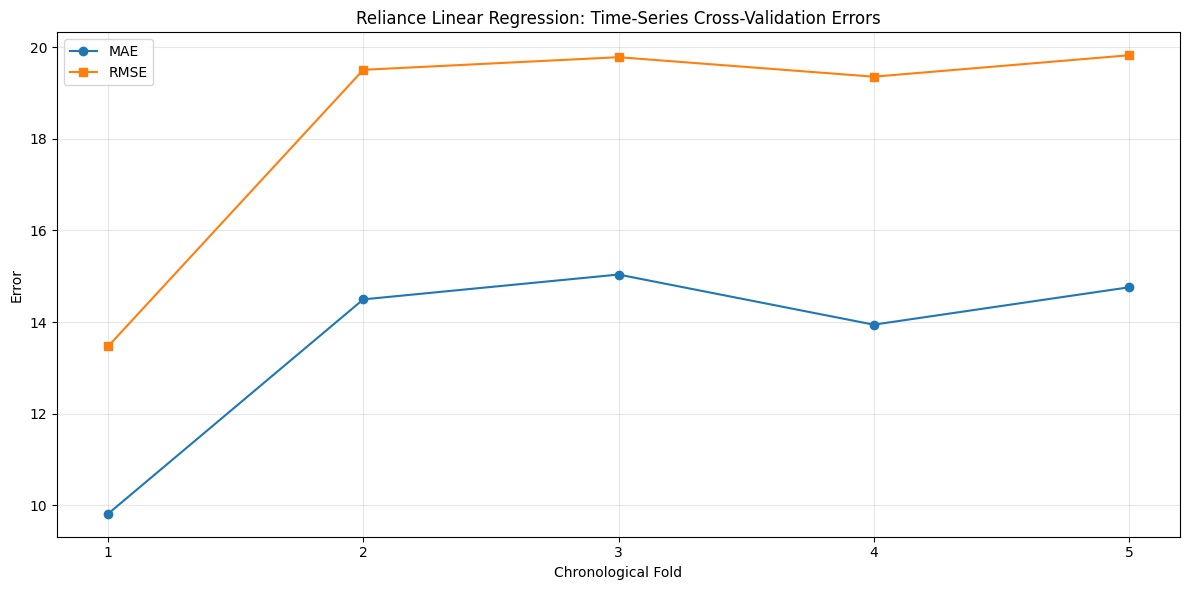


STEP 7 COMPLETED SUCCESSFULLY

WHAT HAPPENED IN THIS STEP?
1. Linear Regression was compared with a chronological baseline.
2. Five expanding-window time-series validation folds were evaluated.
3. MAE, RMSE, R2, MAPE and prediction accuracy were calculated.
4. Mean and standard deviation were calculated across folds.
5. CSV reports and a cross-validation graph were saved.

OUTPUT FILES
Baseline comparison: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_Baseline_Comparison.csv
Cross-validation results: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_TimeSeries_CV_Results.csv
Cross-validation summary: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\linear_regression\Reliance_Linear_Regression_TimeSeries_CV_Summary.csv
Cross-validation graph: C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stoc

In [7]:
# =====================================================
# LINEAR REGRESSION - STEP 7
# Baseline Comparison and Time-Series Cross-Validation
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# 1. Create output directory
output_dir = os.path.join(
    project_path,
    "data",
    "processed",
    "stock",
    "linear_regression"
)

os.makedirs(output_dir, exist_ok=True)

print("=" * 75)
print("STEP 7: BASELINE COMPARISON AND TIME-SERIES CROSS-VALIDATION")
print("=" * 75)

print("\nPURPOSE")
print("1. Compare Linear Regression with a simple stock-price baseline.")
print("2. Evaluate the model across multiple chronological validation folds.")
print("3. Check whether the model performs consistently on unseen data.")

# -----------------------------------------------------
# 2. Baseline comparison on the existing test set
# -----------------------------------------------------

print("\n1. CHRONOLOGICAL BASELINE COMPARISON")
print("-" * 75)

# Baseline: predict next-day Close using today's Close.
baseline_test_pred = X_test["Close"].to_numpy(dtype=float)

actual_test = np.asarray(y_test, dtype=float)
linear_test_pred = linear_model.predict(X_test)

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    nonzero_mask = actual != 0

    if nonzero_mask.any():
        mape = mean_absolute_percentage_error(
            actual[nonzero_mask],
            predicted[nonzero_mask]
        ) * 100

        accuracy = 100 - mape
    else:
        mape = np.nan
        accuracy = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_Percentage": mape,
        "Prediction_Accuracy_Percentage": accuracy
    }

baseline_metrics = calculate_metrics(
    actual_test,
    baseline_test_pred
)

linear_metrics = calculate_metrics(
    actual_test,
    linear_test_pred
)

baseline_comparison_df = pd.DataFrame([
    {"Model": "Chronological Baseline", **baseline_metrics},
    {"Model": "Linear Regression", **linear_metrics}
])

print("\nTest-set performance comparison:")
display(baseline_comparison_df.round(4))

# -----------------------------------------------------
# 3. Compare errors against the baseline
# -----------------------------------------------------

mae_improvement = (
    baseline_metrics["MAE"] - linear_metrics["MAE"]
)

rmse_improvement = (
    baseline_metrics["RMSE"] - linear_metrics["RMSE"]
)

print("\nBASELINE COMPARISON INTERPRETATION")
print("-" * 75)

print(f"MAE improvement: {mae_improvement:.4f}")
print(f"RMSE improvement: {rmse_improvement:.4f}")

if mae_improvement > 0 and rmse_improvement > 0:
    print("Finding: Linear Regression has lower MAE and RMSE")
    print("than the baseline on this test period.")
    print("The model improves on the benchmark for these error metrics.")
elif mae_improvement < 0 and rmse_improvement < 0:
    print("Finding: The baseline has lower MAE and RMSE.")
    print("Linear Regression does not outperform the baseline")
    print("on these error metrics.")
else:
    print("Finding: The results are mixed.")
    print("Compare MAE and RMSE separately to understand performance.")

print("\nNote: This baseline predicts tomorrow's Close using today's Close.")
print("It is a benchmark, not a trained machine-learning model.")

# -----------------------------------------------------
# 4. Time-series cross-validation
# -----------------------------------------------------

print("\n2. TIME-SERIES CROSS-VALIDATION")
print("-" * 75)

# Use the complete feature and target data in chronological order.
# No random shuffling is performed.
X_cv = X.reset_index(drop=True).copy()
y_cv = y.reset_index(drop=True).copy()

# Five expanding-window folds.
tscv = TimeSeriesSplit(n_splits=5)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_cv), start=1
):
    X_fold_train = X_cv.iloc[train_idx]
    y_fold_train = y_cv.iloc[train_idx]

    X_fold_val = X_cv.iloc[val_idx]
    y_fold_val = y_cv.iloc[val_idx]

    # Fit a fresh model for each fold.
    fold_model = clone(linear_model)

    fold_model.fit(X_fold_train, y_fold_train)

    # Generate validation predictions.
    fold_predictions = fold_model.predict(X_fold_val)

    fold_metrics = calculate_metrics(
        y_fold_val,
        fold_predictions
    )

    cv_results.append({
        "Fold": fold,
        "Training_Rows": len(train_idx),
        "Validation_Rows": len(val_idx),
        "Training_Start": df["Date"].iloc[train_idx[0]],
        "Training_End": df["Date"].iloc[train_idx[-1]],
        "Validation_Start": df["Date"].iloc[val_idx[0]],
        "Validation_End": df["Date"].iloc[val_idx[-1]],
        **fold_metrics
    })

    print(f"\nFold {fold} completed.")
    print("Training rows:", len(train_idx))
    print("Validation rows:", len(val_idx))
    print("Validation period:",
          df["Date"].iloc[val_idx[0]],
          "to",
          df["Date"].iloc[val_idx[-1]])

cv_results_df = pd.DataFrame(cv_results)

print("\n3. CROSS-VALIDATION RESULTS")
print("-" * 75)

display(cv_results_df.round(4))

# -----------------------------------------------------
# 5. Calculate average cross-validation performance
# -----------------------------------------------------

metric_columns = [
    "MAE",
    "RMSE",
    "R2",
    "MAPE_Percentage",
    "Prediction_Accuracy_Percentage"
]

cv_summary_df = pd.DataFrame({
    "Metric": metric_columns,
    "Mean": [
        cv_results_df[col].mean()
        for col in metric_columns
    ],
    "Standard_Deviation": [
        cv_results_df[col].std()
        for col in metric_columns
    ]
})

print("\n4. CROSS-VALIDATION SUMMARY")
print("-" * 75)

display(cv_summary_df.round(4))

print("\nInterpretation:")
print("- Mean MAE and RMSE summarize validation errors across folds.")
print("- Standard deviation shows how much each metric varies across folds.")
print("- Lower error variation can indicate more consistent performance.")
print("- R2 may be negative when predictions are worse than a mean-value")
print("  reference for a validation fold.")
print("- Prediction Accuracy is 100 - MAPE, a custom regression indicator.")

# -----------------------------------------------------
# 6. Create and save a cross-validation plot
# -----------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    cv_results_df["Fold"],
    cv_results_df["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    cv_results_df["Fold"],
    cv_results_df["RMSE"],
    marker="s",
    label="RMSE"
)

plt.title(
    "Reliance Linear Regression: Time-Series Cross-Validation Errors"
)
plt.xlabel("Chronological Fold")
plt.ylabel("Error")
plt.xticks(cv_results_df["Fold"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

cv_graph_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_TimeSeries_CV.png"
)

plt.savefig(cv_graph_path, dpi=300, bbox_inches="tight")
plt.show()

# -----------------------------------------------------
# 7. Save all results
# -----------------------------------------------------

baseline_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_Baseline_Comparison.csv"
)

cv_results_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_TimeSeries_CV_Results.csv"
)

cv_summary_path = os.path.join(
    output_dir,
    "Reliance_Linear_Regression_TimeSeries_CV_Summary.csv"
)

baseline_comparison_df.to_csv(
    baseline_path, index=False
)

cv_results_df.to_csv(
    cv_results_path, index=False
)

cv_summary_df.to_csv(
    cv_summary_path, index=False
)

# -----------------------------------------------------
# 8. Final summary
# -----------------------------------------------------

print("\n" + "=" * 75)
print("STEP 7 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("\nWHAT HAPPENED IN THIS STEP?")
print("1. Linear Regression was compared with a chronological baseline.")
print("2. Five expanding-window time-series validation folds were evaluated.")
print("3. MAE, RMSE, R2, MAPE and prediction accuracy were calculated.")
print("4. Mean and standard deviation were calculated across folds.")
print("5. CSV reports and a cross-validation graph were saved.")

print("\nOUTPUT FILES")
print("Baseline comparison:", baseline_path)
print("Cross-validation results:", cv_results_path)
print("Cross-validation summary:", cv_summary_path)
print("Cross-validation graph:", cv_graph_path)

print("\nFINAL INTERPRETATION")
print("Use the baseline comparison and cross-validation results together")
print("to assess how reliably Linear Regression generalizes.")
print("These results provide stronger evidence, but do not alone prove")
print("or rule out overfitting.")

print("\nAll Step 7 outputs are stored in:")
print(output_dir)

STEP 8: OVERFITTING MITIGATION

DATASET VERIFICATION
----------------------------------------
Dataset shape after validation: (2400, 7)
Start date: 2017-01-02
End date:   2026-09-17
Missing values remaining: 0
Duplicate dates: 0
Features: ['Open', 'High', 'Low', 'Close', 'Volume']
Target: Next_Day_Close

CHRONOLOGICAL DATA SPLIT
----------------------------------------
Training observations: 1919
Testing observations:  480
Training period: 2017-01-02 to 2024-10-09
Testing period:  2024-10-11 to 2026-09-17
Shuffle: Disabled

TRAINING AND TUNING MODELS
----------------------------------------
Linear Regression: training completed.
Ridge Regression: best alpha = 0.01
Lasso Regression: best alpha = 0.1

TRAINING AND TEST METRICS
----------------------------------------------------------------------
            Model Dataset  Best_Alpha  Best_CV_MAE     MAE    RMSE  R2_Score  MAPE_Percentage  Prediction_Accuracy_Percentage
Linear Regression   Train         NaN          NaN 11.4208 16.3447  

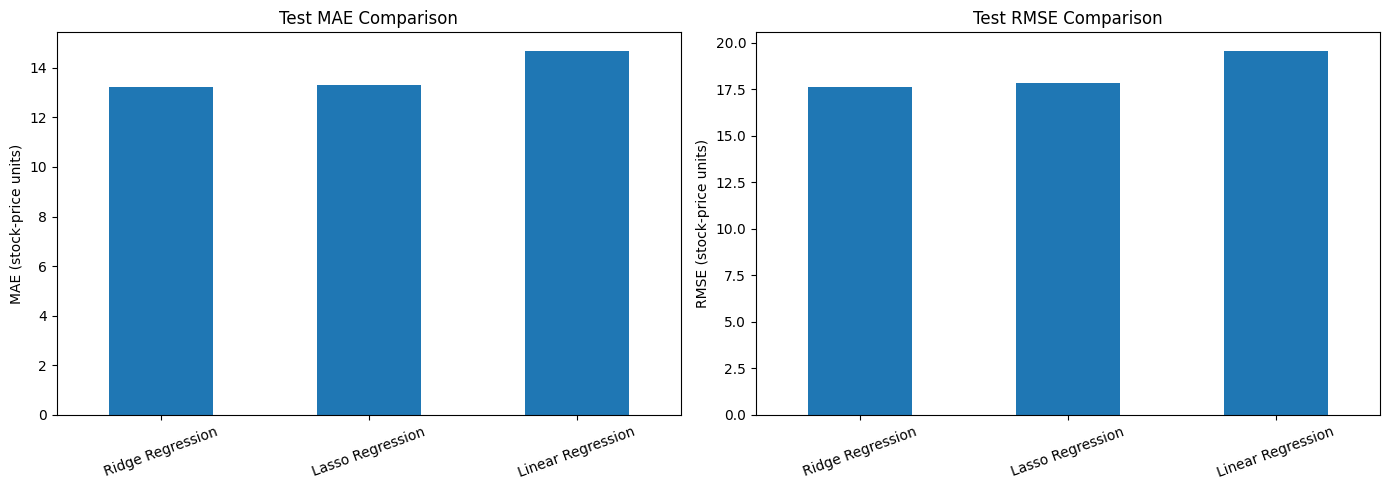

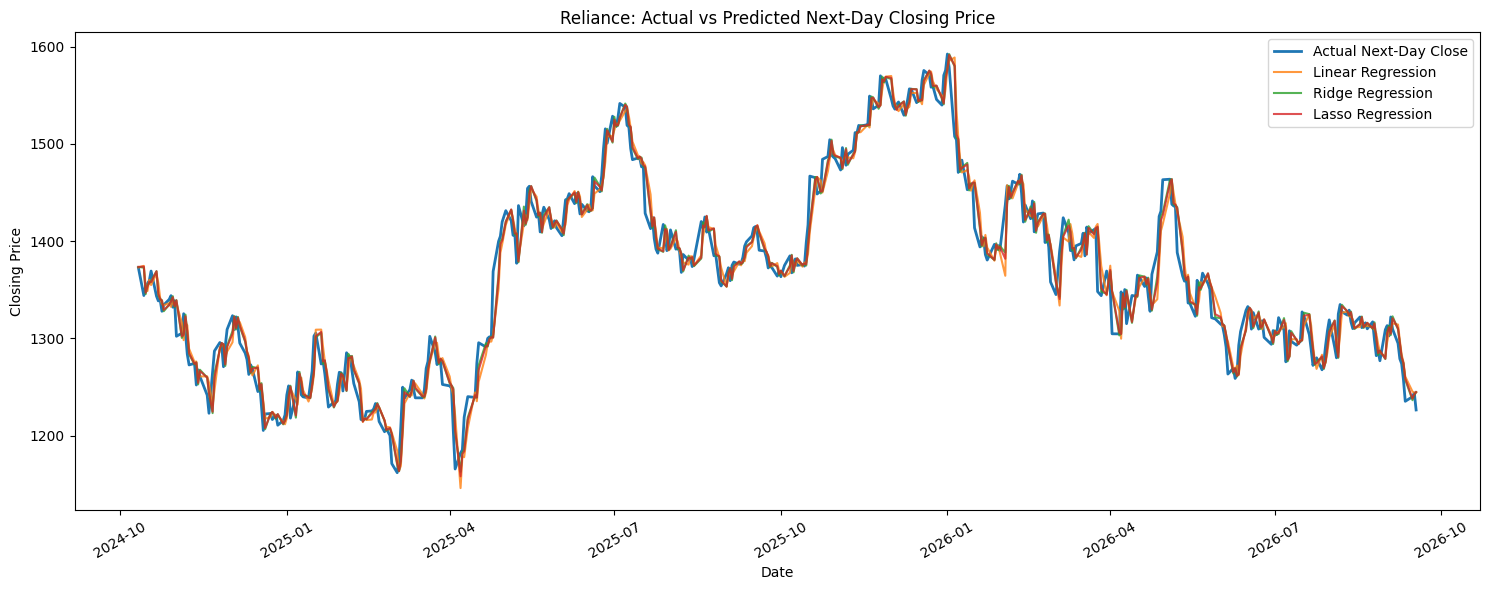

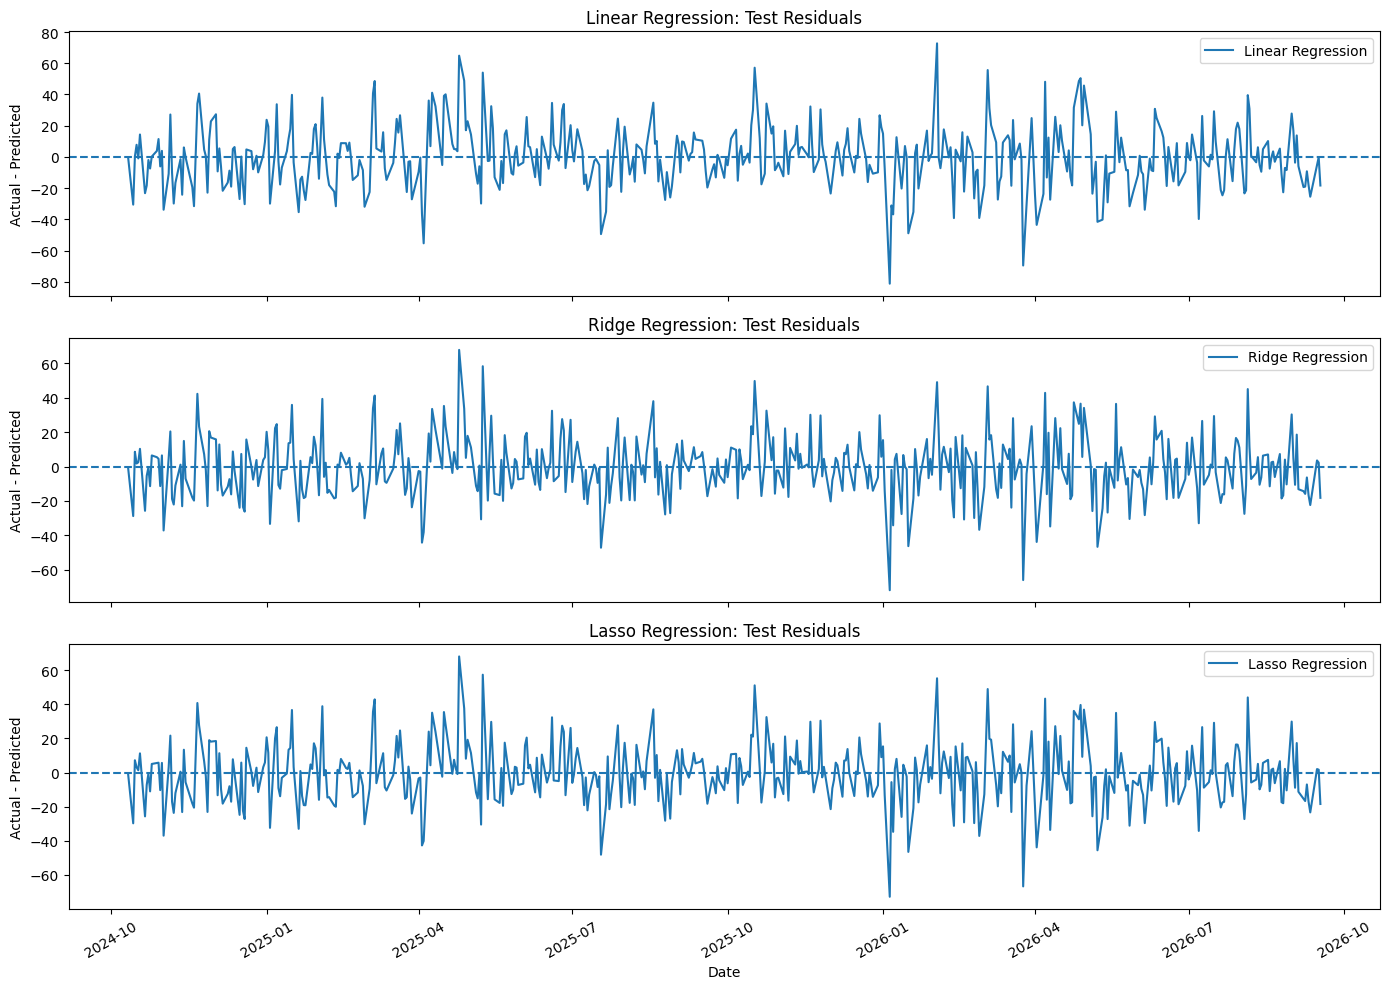

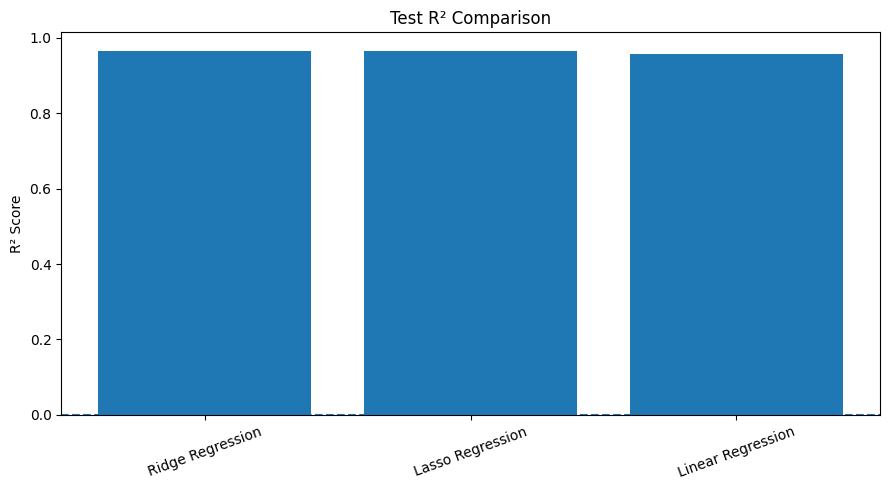


STEP 8 COMPLETED: OVERFITTING MITIGATION RESULTS

1. BEST MODEL RESULTS
--------------------------------------------------------------------------------
Best model by MAE  : Ridge Regression
Best model by RMSE : Ridge Regression
Best model by R2   : Ridge Regression

Actual test metrics for the best MAE model:
MAE                : 13.2194
RMSE               : 17.5912
R2 Score           : 0.9662
MAPE               : 0.98%
Prediction indicator: 99.02%

INTERPRETATION:
Ridge Regression has the lowest test MAE among the three models. Its average absolute prediction error is therefore the smallest according to this metric.
The same model, Ridge Regression, also has the lowest test RMSE and highest test R2. All three criteria agree on the best model in this comparison.


2. HOW TO UNDERSTAND THE METRICS
--------------------------------------------------------------------------------
MAE:
Measures the average absolute difference between actual and predicted stock prices. Lower is better.

RM

In [9]:
# ================================================================
# STEP 8: OVERFITTING MITIGATION
# Reliance Industries Stock Price Prediction
# Models: Linear Regression, Ridge Regression, Lasso Regression
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------

DATA_PATH = (
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
    r"\data\processed\stock\Reliance_Prepared_Data_2017_2026.csv"
)

OUTPUT_DIR = (
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
    r"\data\processed\stock\step_8_overfitting_mitigation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

FEATURES = ["Open", "High", "Low", "Close", "Volume"]
TARGET = "Next_Day_Close"

print("=" * 70)
print("STEP 8: OVERFITTING MITIGATION")
print("=" * 70)


# ------------------------------------------------
# 2. LOAD AND VALIDATE DATA
# ------------------------------------------------

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found. Please verify this path:\n{DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

required_columns = ["Date"] + FEATURES + [TARGET]
missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for column in FEATURES + [TARGET]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows with invalid dates, missing values or infinities
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=required_columns)
df = df.sort_values("Date").reset_index(drop=True)

if df["Date"].duplicated().any():
    raise ValueError(
        "Duplicate dates found. Resolve duplicate dates before training."
    )

if len(df) < 100:
    raise ValueError(
        "Insufficient valid observations for this experiment."
    )

print("\nDATASET VERIFICATION")
print("-" * 40)
print(f"Dataset shape after validation: {df.shape}")
print(f"Start date: {df['Date'].min().date()}")
print(f"End date:   {df['Date'].max().date()}")
print(f"Missing values remaining: {df[required_columns].isna().sum().sum()}")
print(f"Duplicate dates: {df['Date'].duplicated().sum()}")
print(f"Features: {FEATURES}")
print(f"Target: {TARGET}")


# ------------------------------------------------
# 3. SAME CHRONOLOGICAL TRAIN/TEST SPLIT
# ------------------------------------------------

# Keep the same split convention used in the earlier steps.
# No random shuffling is performed.

X = df[FEATURES].copy()
y = df[TARGET].copy()
dates = df["Date"].copy()

split_index = int(len(df) * 0.80)
train_end = split_index - 1

X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_test = X.iloc[split_index:].copy()
y_test = y.iloc[split_index:].copy()

train_dates = dates.iloc[:train_end].copy()
test_dates = dates.iloc[split_index:].copy()

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("The chronological split produced an empty dataset.")

print("\nCHRONOLOGICAL DATA SPLIT")
print("-" * 40)
print(f"Training observations: {len(X_train)}")
print(f"Testing observations:  {len(X_test)}")
print(f"Training period: {train_dates.min().date()} to "
      f"{train_dates.max().date()}")
print(f"Testing period:  {test_dates.min().date()} to "
      f"{test_dates.max().date()}")
print("Shuffle: Disabled")

# Note: As in the previous split, the row at split_index - 1
# is excluded. This preserves consistency with earlier results.


# ------------------------------------------------
# 4. DEFINE THE MODELS
# ------------------------------------------------

# Linear Regression: no regularization
linear_model = LinearRegression()

# Ridge and Lasso use StandardScaler inside their pipelines.
# The scaler is fitted only on training folds during CV.

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=100000))
])

# Tune regularization strength using chronological CV
alpha_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

time_cv = TimeSeriesSplit(n_splits=5)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=-1,
    refit=True
)

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=-1,
    refit=True
)

print("\nTRAINING AND TUNING MODELS")
print("-" * 40)

linear_model.fit(X_train, y_train)
print("Linear Regression: training completed.")

ridge_search.fit(X_train, y_train)
print(f"Ridge Regression: best alpha = "
      f"{ridge_search.best_params_['model__alpha']}")

lasso_search.fit(X_train, y_train)
print(f"Lasso Regression: best alpha = "
      f"{lasso_search.best_params_['model__alpha']}")

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_search.best_estimator_,
    "Lasso Regression": lasso_search.best_estimator_
}

best_alpha = {
    "Linear Regression": np.nan,
    "Ridge Regression": ridge_search.best_params_["model__alpha"],
    "Lasso Regression": lasso_search.best_params_["model__alpha"]
}

best_cv_mae = {
    "Linear Regression": np.nan,
    "Ridge Regression": -ridge_search.best_score_,
    "Lasso Regression": -lasso_search.best_score_
}


# ------------------------------------------------
# 5. EVALUATION FUNCTION
# ------------------------------------------------

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100

    # Custom regression indicator, NOT classification accuracy
    prediction_accuracy = 100 - mape

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2_Score": r2,
        "MAPE_Percentage": mape,
        "Prediction_Accuracy_Percentage": prediction_accuracy
    }


# ------------------------------------------------
# 6. EVALUATE TRAINING AND TEST PERFORMANCE
# ------------------------------------------------

metrics_rows = []
prediction_data = pd.DataFrame({
    "Date": test_dates.to_numpy(),
    "Actual_Next_Day_Close": y_test.to_numpy()
})

residual_data = {}

for name, model in models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_metrics = calculate_metrics(y_train, train_pred)
    test_metrics = calculate_metrics(y_test, test_pred)

    metrics_rows.append({
        "Model": name,
        "Dataset": "Train",
        "Best_Alpha": best_alpha[name],
        "Best_CV_MAE": best_cv_mae[name],
        **train_metrics
    })

    metrics_rows.append({
        "Model": name,
        "Dataset": "Test",
        "Best_Alpha": best_alpha[name],
        "Best_CV_MAE": best_cv_mae[name],
        **test_metrics
    })

    prediction_data[f"{name}_Prediction"] = test_pred
    prediction_data[f"{name}_Residual"] = (
        y_test.to_numpy() - test_pred
    )

    residual_data[name] = y_test.to_numpy() - test_pred

metrics_df = pd.DataFrame(metrics_rows)

print("\nTRAINING AND TEST METRICS")
print("-" * 70)
print(metrics_df.round(4).to_string(index=False))


# ------------------------------------------------
# 7. CREATE TEST-ONLY MODEL COMPARISON TABLE
# ------------------------------------------------

test_comparison = metrics_df[
    metrics_df["Dataset"] == "Test"
].copy()

# Lower MAE and RMSE are better.
# Higher R2 is better; negative R2 is possible.
test_comparison = test_comparison.sort_values(
    by="MAE", ascending=True
).reset_index(drop=True)

test_comparison.insert(
    0, "MAE_Rank", np.arange(1, len(test_comparison) + 1)
)

print("\nTEST PERFORMANCE COMPARISON")
print("-" * 70)
print(test_comparison.round(4).to_string(index=False))

best_mae_model = test_comparison.iloc[0]["Model"]
best_rmse_model = (
    test_comparison.sort_values("RMSE").iloc[0]["Model"]
)
best_r2_model = (
    test_comparison.sort_values("R2_Score", ascending=False)
    .iloc[0]["Model"]
)

print("\nAUTOMATIC FINDINGS")
print("-" * 40)
print(f"Lowest test MAE:  {best_mae_model}")
print(f"Lowest test RMSE: {best_rmse_model}")
print(f"Highest test R2: {best_r2_model}")


# ------------------------------------------------
# 8. OVERFITTING / GENERALIZATION GAP ANALYSIS
# ------------------------------------------------

gap_rows = []

for name in models:
    train_row = metrics_df[
        (metrics_df["Model"] == name) &
        (metrics_df["Dataset"] == "Train")
    ].iloc[0]

    test_row = metrics_df[
        (metrics_df["Model"] == name) &
        (metrics_df["Dataset"] == "Test")
    ].iloc[0]

    gap_rows.append({
        "Model": name,
        "Train_MAE": train_row["MAE"],
        "Test_MAE": test_row["MAE"],
        "MAE_Gap_Test_Minus_Train": (
            test_row["MAE"] - train_row["MAE"]
        ),
        "Train_RMSE": train_row["RMSE"],
        "Test_RMSE": test_row["RMSE"],
        "RMSE_Gap_Test_Minus_Train": (
            test_row["RMSE"] - train_row["RMSE"]
        ),
        "Train_R2": train_row["R2_Score"],
        "Test_R2": test_row["R2_Score"],
        "R2_Gap_Train_Minus_Test": (
            train_row["R2_Score"] - test_row["R2_Score"]
        )
    })

gap_df = pd.DataFrame(gap_rows)

print("\nGENERALIZATION GAP ANALYSIS")
print("-" * 70)
print(gap_df.round(4).to_string(index=False))


# ------------------------------------------------
# 9. SAVE CSV OUTPUT FILES
# ------------------------------------------------

metrics_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Train_Test_Metrics.csv"
)

comparison_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Test_Model_Comparison.csv"
)

predictions_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Test_Predictions.csv"
)

gap_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Generalization_Gap.csv"
)

ridge_cv_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Ridge_CV_Results.csv"
)

lasso_cv_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Lasso_CV_Results.csv"
)

metrics_df.to_csv(metrics_path, index=False)
test_comparison.to_csv(comparison_path, index=False)
prediction_data.to_csv(predictions_path, index=False)
gap_df.to_csv(gap_path, index=False)

# Save all alpha-search results, including chronological CV scores
pd.DataFrame(ridge_search.cv_results_).to_csv(
    ridge_cv_path, index=False
)

pd.DataFrame(lasso_search.cv_results_).to_csv(
    lasso_cv_path, index=False
)


# ------------------------------------------------
# 10. GRAPH 1: TEST MAE AND RMSE COMPARISON
# ------------------------------------------------

plot_data = test_comparison.set_index("Model")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_data["MAE"].plot(
    kind="bar", ax=axes[0], title="Test MAE Comparison"
)
axes[0].set_ylabel("MAE (stock-price units)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)

plot_data["RMSE"].plot(
    kind="bar", ax=axes[1], title="Test RMSE Comparison"
)
axes[1].set_ylabel("RMSE (stock-price units)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()

mae_rmse_plot_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_MAE_RMSE_Comparison.png"
)

plt.savefig(mae_rmse_plot_path, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------
# 11. GRAPH 2: ACTUAL VS PREDICTED PRICES
# ------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates, y_test.to_numpy(),
    label="Actual Next-Day Close", linewidth=2
)

for name in models:
    plt.plot(
        test_dates,
        prediction_data[f"{name}_Prediction"],
        label=name,
        alpha=0.8
    )

plt.title("Reliance: Actual vs Predicted Next-Day Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()

actual_pred_plot_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Actual_vs_Predicted.png"
)

plt.savefig(actual_pred_plot_path, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------
# 12. GRAPH 3: TEST RESIDUALS OVER TIME
# ------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, name in zip(axes, models):
    ax.plot(
        test_dates,
        residual_data[name],
        label=name
    )
    ax.axhline(0, linestyle="--")
    ax.set_title(f"{name}: Test Residuals")
    ax.set_ylabel("Actual - Predicted")
    ax.legend()

axes[-1].set_xlabel("Date")
plt.xticks(rotation=30)
plt.tight_layout()

residual_plot_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_Residuals_Over_Time.png"
)

plt.savefig(residual_plot_path, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------
# 13. GRAPH 4: TEST R2 COMPARISON
# ------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    test_comparison["Model"],
    test_comparison["R2_Score"]
)

plt.axhline(0, linestyle="--")
plt.title("Test R² Comparison")
plt.ylabel("R² Score")
plt.xticks(rotation=20)
plt.tight_layout()

r2_plot_path = os.path.join(
    OUTPUT_DIR, "Reliance_Step8_R2_Comparison.png"
)

plt.savefig(r2_plot_path, dpi=300, bbox_inches="tight")
plt.show()


# ================================================================
# 14. FINAL SUMMARY + AUTOMATIC INTERPRETATION
# ================================================================

print("\n" + "=" * 80)
print("STEP 8 COMPLETED: OVERFITTING MITIGATION RESULTS")
print("=" * 80)

# ------------------------------------------------
# A. DISPLAY THE BEST MODEL AND ITS ACTUAL METRICS
# ------------------------------------------------

test_results = metrics_df[
    metrics_df["Dataset"] == "Test"
].copy()

train_results = metrics_df[
    metrics_df["Dataset"] == "Train"
].copy()

test_results = test_results.set_index("Model")
train_results = train_results.set_index("Model")

best_mae_model = test_results["MAE"].idxmin()
best_rmse_model = test_results["RMSE"].idxmin()
best_r2_model = test_results["R2_Score"].idxmax()

print("\n1. BEST MODEL RESULTS")
print("-" * 80)

print(f"Best model by MAE  : {best_mae_model}")
print(f"Best model by RMSE : {best_rmse_model}")
print(f"Best model by R2   : {best_r2_model}")

print("\nActual test metrics for the best MAE model:")

best_result = test_results.loc[best_mae_model]

print(f"MAE                : {best_result['MAE']:.4f}")
print(f"RMSE               : {best_result['RMSE']:.4f}")
print(f"R2 Score           : {best_result['R2_Score']:.4f}")
print(f"MAPE               : {best_result['MAPE_Percentage']:.2f}%")
print(
    "Prediction indicator: "
    f"{best_result['Prediction_Accuracy_Percentage']:.2f}%"
)

print("\nINTERPRETATION:")
print(
    f"{best_mae_model} has the lowest test MAE among the three "
    "models. Its average absolute prediction error is therefore "
    "the smallest according to this metric."
)

if (
    best_mae_model == best_rmse_model
    and best_mae_model == best_r2_model
):
    print(
        f"The same model, {best_mae_model}, also has the lowest "
        "test RMSE and highest test R2. All three criteria agree "
        "on the best model in this comparison."
    )
else:
    print(
        "The metrics do not all select the same model. Consider "
        "MAE, RMSE, R2 and the baseline together before selecting "
        "a final model."
    )


# ------------------------------------------------
# B. EXPLAIN WHAT THE METRICS MEAN
# ------------------------------------------------

print("\n\n2. HOW TO UNDERSTAND THE METRICS")
print("-" * 80)

print("MAE:")
print(
    "Measures the average absolute difference between actual "
    "and predicted stock prices. Lower is better."
)

print("\nRMSE:")
print(
    "Penalizes large prediction errors more strongly than MAE. "
    "Lower is better."
)

print("\nR2 SCORE:")
print(
    "Measures performance relative to predicting the test-set "
    "mean. A score closer to 1 is generally better; a negative "
    "score means the model performed worse than that mean-based "
    "reference on the evaluated data."
)

print("\nMAPE:")
print(
    "Expresses the average absolute prediction error as a "
    "percentage of actual values. Lower is better."
)

print("\nCUSTOM PREDICTION INDICATOR:")
print(
    "Calculated as 100 - MAPE. It is NOT classification accuracy "
    "and is not a standard stock-prediction accuracy metric. "
    "It can be negative when MAPE exceeds 100%."
)


# ------------------------------------------------
# C. COMPARE RIDGE AND LASSO AGAINST LINEAR REGRESSION
# ------------------------------------------------

print("\n\n3. DID REGULARIZATION IMPROVE TEST PERFORMANCE?")
print("-" * 80)

linear_test = test_results.loc["Linear Regression"]

for model_name in ["Ridge Regression", "Lasso Regression"]:

    model_test = test_results.loc[model_name]

    print(f"\n{model_name} vs Linear Regression:")

    for metric in ["MAE", "RMSE"]:

        linear_value = linear_test[metric]
        model_value = model_test[metric]

        difference = linear_value - model_value

        if linear_value != 0:
            improvement_pct = (
                difference / abs(linear_value)
            ) * 100
        else:
            improvement_pct = np.nan

        print(
            f"{metric}: Linear = {linear_value:.4f}, "
            f"{model_name} = {model_value:.4f}"
        )

        if difference > 0:
            print(
                f"  Improvement: error decreased by "
                f"{difference:.4f} ({improvement_pct:.2f}%)."
            )
        elif difference < 0:
            print(
                f"  Result: error increased by "
                f"{abs(difference):.4f} "
                f"({abs(improvement_pct):.2f}%)."
            )
        else:
            print("  Result: both models have the same error.")

    r2_difference = (
        model_test["R2_Score"] - linear_test["R2_Score"]
    )

    print(
        f"R2 change compared with Linear Regression: "
        f"{r2_difference:+.4f}"
    )

    if (
        model_test["MAE"] < linear_test["MAE"]
        and model_test["RMSE"] < linear_test["RMSE"]
        and model_test["R2_Score"] > linear_test["R2_Score"]
    ):
        print(
            "Interpretation: this model improved all three "
            "test metrics compared with Linear Regression."
        )
    else:
        print(
            "Interpretation: this model did not improve all three "
            "test metrics. Review each metric separately."
        )


# ------------------------------------------------
# D. EXPLAIN THE GENERALIZATION GAP
# ------------------------------------------------

print("\n\n4. OVERFITTING AND GENERALIZATION GAP ANALYSIS")
print("-" * 80)

print(
    "A large difference between training and test performance "
    "can indicate a generalization problem. It does not prove "
    "overfitting by itself."
)

for model_name in models:

    train_row = train_results.loc[model_name]
    test_row = test_results.loc[model_name]

    mae_gap = test_row["MAE"] - train_row["MAE"]
    rmse_gap = test_row["RMSE"] - train_row["RMSE"]
    r2_gap = train_row["R2_Score"] - test_row["R2_Score"]

    print(f"\n{model_name}")
    print(f"  Training MAE : {train_row['MAE']:.4f}")
    print(f"  Testing MAE  : {test_row['MAE']:.4f}")
    print(f"  MAE gap      : {mae_gap:+.4f}")

    print(f"  Training RMSE: {train_row['RMSE']:.4f}")
    print(f"  Testing RMSE : {test_row['RMSE']:.4f}")
    print(f"  RMSE gap     : {rmse_gap:+.4f}")

    print(f"  Training R2  : {train_row['R2_Score']:.4f}")
    print(f"  Testing R2   : {test_row['R2_Score']:.4f}")
    print(f"  R2 gap       : {r2_gap:+.4f}")

    if mae_gap > 0 and rmse_gap > 0:
        print(
            "  Interpretation: both test errors are higher than "
            "training errors. This indicates a generalization "
            "gap that deserves investigation."
        )
    elif mae_gap <= 0 and rmse_gap <= 0:
        print(
            "  Interpretation: test errors are not higher than "
            "training errors for these two metrics. There is no "
            "positive MAE/RMSE gap in this comparison."
        )
    else:
        print(
            "  Interpretation: MAE and RMSE show different "
            "train-test patterns. Inspect both metrics and the "
            "residual graph."
        )


# Compare positive MAE and RMSE gaps with the Linear Regression gap.
linear_gap = gap_df[
    gap_df["Model"] == "Linear Regression"
].iloc[0]

print("\n\nGENERALIZATION GAP COMPARISON WITH LINEAR REGRESSION")
print("-" * 80)

for model_name in ["Ridge Regression", "Lasso Regression"]:

    row = gap_df[gap_df["Model"] == model_name].iloc[0]

    print(f"\n{model_name}:")

    for gap_column, label in [
        ("MAE_Gap_Test_Minus_Train", "MAE gap"),
        ("RMSE_Gap_Test_Minus_Train", "RMSE gap")
    ]:

        baseline_gap = linear_gap[gap_column]
        model_gap = row[gap_column]

        print(
            f"  Linear Regression {label}: {baseline_gap:+.4f}"
        )
        print(f"  {model_name} {label}: {model_gap:+.4f}")

        if baseline_gap >= 0 and model_gap >= 0:
            if model_gap < baseline_gap:
                print(
                    f"  Finding: the positive {label} is smaller "
                    "than Linear Regression's gap."
                )
            elif model_gap > baseline_gap:
                print(
                    f"  Finding: the positive {label} is larger "
                    "than Linear Regression's gap."
                )
            else:
                print(f"  Finding: the {label} is unchanged.")
        else:
            print(
                "  Finding: at least one gap is non-positive, "
                "so compare the signed values and actual errors "
                "rather than treating gap size alone as proof."
            )


# ------------------------------------------------
# E. FINAL AUTOMATIC CONCLUSION
# ------------------------------------------------

print("\n\n" + "=" * 80)
print("5. FINAL CONCLUSION FOR STEP 8")
print("=" * 80)

ridge_test = test_results.loc["Ridge Regression"]
lasso_test = test_results.loc["Lasso Regression"]

ridge_train = train_results.loc["Ridge Regression"]
lasso_train = train_results.loc["Lasso Regression"]

ridge_improved_errors = (
    ridge_test["MAE"] < linear_test["MAE"]
    and ridge_test["RMSE"] < linear_test["RMSE"]
)

ridge_improved_r2 = (
    ridge_test["R2_Score"] > linear_test["R2_Score"]
)

if ridge_improved_errors and ridge_improved_r2:
    print(
        "RESULT: Ridge Regression improved MAE, RMSE and R2 "
        "on the held-out test set compared with Linear Regression."
    )
elif ridge_improved_errors:
    print(
        "RESULT: Ridge Regression reduced both test MAE and RMSE, "
        "but it did not improve all three test metrics."
    )
else:
    print(
        "RESULT: Ridge Regression did not reduce both test MAE "
        "and RMSE compared with Linear Regression."
    )

ridge_gap_smaller = (
    gap_df.loc[
        gap_df["Model"] == "Ridge Regression",
        "MAE_Gap_Test_Minus_Train"
    ].iloc[0]
    <
    gap_df.loc[
        gap_df["Model"] == "Linear Regression",
        "MAE_Gap_Test_Minus_Train"
    ].iloc[0]
)

if ridge_gap_smaller:
    print(
        "GENERALIZATION: Ridge has a smaller signed MAE gap "
        "than Linear Regression. Inspect actual errors as well "
        "because a gap alone does not prove less overfitting."
    )
else:
    print(
        "GENERALIZATION: Ridge does not have a smaller signed "
        "MAE gap than Linear Regression."
    )

print(
    "\nIMPORTANT: The best model in this comparison is not "
    "automatically the best model overall. Compare its test "
    "MAE and RMSE against the Step 7 persistence baseline."
)

print(
    "\nOVERFITTING CONCLUSION: Regularization has been tested, "
    "but overfitting can only be considered mitigated if the "
    "evidence supports improved unseen-data performance and "
    "a reasonable generalization gap."
)

print(
    "\nThe final selected model should be based on actual test "
    "metrics, the generalization gap, residual behaviour and "
    "baseline comparison—not on the model name alone."
)


# ------------------------------------------------
# F. CONFIRM SAVED FILES
# ------------------------------------------------

print("\n\n6. SAVED OUTPUT FILES")
print("-" * 80)

output_files = [
    metrics_path,
    comparison_path,
    predictions_path,
    gap_path,
    ridge_cv_path,
    lasso_cv_path,
    mae_rmse_plot_path,
    actual_pred_plot_path,
    residual_plot_path,
    r2_plot_path
]

for file_path in output_files:
    status = "SAVED" if os.path.exists(file_path) else "NOT FOUND"
    print(f"[{status}] {file_path}")

print("\nSTEP 8 INTERPRETATION FINISHED.")
print("Use the actual results above in your project report.")
print("=" * 80)



In [10]:
import os
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================================
# STEP 9: LINEAR REGRESSION TRAINING AND VALIDATION
# ==========================================================

# Use only the training data from Step 8.
# Reserve the last 20% of training data for validation.
split_index = int(len(X_train) * 0.80)

X_train_lr = X_train.iloc[:split_index]
X_val_lr = X_train.iloc[split_index:]

y_train_lr = y_train.iloc[:split_index]
y_val_lr = y_train.iloc[split_index:]

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_lr, y_train_lr)

# Predictions
train_predictions = lr_model.predict(X_train_lr)
val_predictions = lr_model.predict(X_val_lr)

# Calculate metrics
def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

train_metrics = calculate_metrics(y_train_lr, train_predictions)
val_metrics = calculate_metrics(y_val_lr, val_predictions)

# Display training and validation results
results_df = pd.DataFrame([
    {"Dataset": "Training", **train_metrics},
    {"Dataset": "Validation", **val_metrics}
])

print("=" * 65)
print("RELIANCE STOCK PRICE: LINEAR REGRESSION")
print("TRAINING AND VALIDATION RESULTS")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

# Generalization gaps
mae_gap = val_metrics["MAE"] - train_metrics["MAE"]
rmse_gap = val_metrics["RMSE"] - train_metrics["RMSE"]
r2_gap = train_metrics["R2"] - val_metrics["R2"]

print("\nGENERALIZATION GAP")
print("-" * 65)
print(f"MAE gap  (Validation - Training): {mae_gap:.4f}")
print(f"RMSE gap (Validation - Training): {rmse_gap:.4f}")
print(f"R2 gap   (Training - Validation): {r2_gap:.4f}")

# Automatic interpretation
print("\nINTERPRETATION")
print("-" * 65)

if (
    val_metrics["MAE"] > train_metrics["MAE"]
    and val_metrics["RMSE"] > train_metrics["RMSE"]
    and val_metrics["R2"] < train_metrics["R2"]
):
    print(
        "Validation performance is worse than training performance "
        "across all three metrics. This is a possible sign of "
        "overfitting, but the gap size and validation results "
        "must also be examined."
    )
elif (
    val_metrics["MAE"] <= train_metrics["MAE"]
    and val_metrics["RMSE"] <= train_metrics["RMSE"]
):
    print(
        "Validation errors are no higher than training errors. "
        "There is no clear overfitting signal from these error "
        "metrics in this split."
    )
else:
    print(
        "The metrics give mixed evidence. Review the size of the "
        "generalization gaps and the validation scores before "
        "drawing a conclusion about overfitting."
    )

print(
    "\nNote: A small gap does not automatically mean a good model. "
    "Check the absolute validation errors and R2 as well."
)

# Save results
output_dir = (
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
    r"\data\processed\stock\step_9_linear_regression_validation"
)
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(
    os.path.join(output_dir, "Reliance_Linear_Regression_Train_Validation.csv"),
    index=False
)

gap_df = pd.DataFrame([{
    "MAE_Gap": mae_gap,
    "RMSE_Gap": rmse_gap,
    "R2_Gap": r2_gap
}])

gap_df.to_csv(
    os.path.join(output_dir, "Reliance_Linear_Regression_Generalization_Gap.csv"),
    index=False
)

print("\nResults saved in:")
print(output_dir)


RELIANCE STOCK PRICE: LINEAR REGRESSION
TRAINING AND VALIDATION RESULTS
   Dataset     MAE    RMSE     R2
  Training 10.9707 15.6929 0.9974
Validation 13.2880 18.7754 0.9851

GENERALIZATION GAP
-----------------------------------------------------------------
MAE gap  (Validation - Training): 2.3173
RMSE gap (Validation - Training): 3.0825
R2 gap   (Training - Validation): 0.0123

INTERPRETATION
-----------------------------------------------------------------
Validation performance is worse than training performance across all three metrics. This is a possible sign of overfitting, but the gap size and validation results must also be examined.

Note: A small gap does not automatically mean a good model. Check the absolute validation errors and R2 as well.

Results saved in:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\step_9_linear_regression_validation


In [11]:
import os
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================================
# STEP 10: COMPARE LINEAR REGRESSION AND RIDGE REGRESSION
# ==========================================================

# 1. Same chronological split for both models
split_index = int(len(X_train) * 0.80)

X_train_lr = X_train.iloc[:split_index]
X_val_lr = X_train.iloc[split_index:]

y_train_lr = y_train.iloc[:split_index]
y_val_lr = y_train.iloc[split_index:]

# 2. Define both models
linear_model = LinearRegression()

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=0.01))
])

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model
}

# 3. Train and evaluate both models
results = []

for name, model in models.items():
    model.fit(X_train_lr, y_train_lr)

    train_pred = model.predict(X_train_lr)
    val_pred = model.predict(X_val_lr)

    results.append({
        "Model": name,
        "Train_MAE": mean_absolute_error(y_train_lr, train_pred),
        "Validation_MAE": mean_absolute_error(y_val_lr, val_pred),
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train_lr, train_pred)
        ),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(y_val_lr, val_pred)
        ),
        "Train_R2": r2_score(y_train_lr, train_pred),
        "Validation_R2": r2_score(y_val_lr, val_pred)
    })

comparison_df = pd.DataFrame(results)

# 4. Calculate generalization gaps
comparison_df["MAE_Gap"] = (
    comparison_df["Validation_MAE"] - comparison_df["Train_MAE"]
)

comparison_df["RMSE_Gap"] = (
    comparison_df["Validation_RMSE"] - comparison_df["Train_RMSE"]
)

comparison_df["R2_Gap"] = (
    comparison_df["Train_R2"] - comparison_df["Validation_R2"]
)

# 5. Display results
print("=" * 90)
print("RELIANCE: LINEAR REGRESSION VS RIDGE REGRESSION")
print("CHRONOLOGICAL TRAINING-VALIDATION COMPARISON")
print("=" * 90)

print(comparison_df.round(4).to_string(index=False))

# 6. Compare validation errors
linear = comparison_df[
    comparison_df["Model"] == "Linear Regression"
].iloc[0]

ridge = comparison_df[
    comparison_df["Model"] == "Ridge Regression"
].iloc[0]

print("\n" + "=" * 65)
print("AUTOMATIC INTERPRETATION")
print("=" * 65)

mae_improvement = (
    (linear["Validation_MAE"] - ridge["Validation_MAE"])
    / linear["Validation_MAE"] * 100
)

rmse_improvement = (
    (linear["Validation_RMSE"] - ridge["Validation_RMSE"])
    / linear["Validation_RMSE"] * 100
)

print(f"Ridge validation MAE improvement:  {mae_improvement:.2f}%")
print(f"Ridge validation RMSE improvement: {rmse_improvement:.2f}%")

if (
    ridge["Validation_MAE"] < linear["Validation_MAE"]
    and ridge["Validation_RMSE"] < linear["Validation_RMSE"]
    and ridge["R2_Gap"] < linear["R2_Gap"]
):
    print(
        "\nCONCLUSION: Ridge has lower validation errors and a smaller "
        "R2 gap. These results support improved generalization "
        "for this split."
    )
elif (
    ridge["Validation_MAE"] < linear["Validation_MAE"]
    and ridge["Validation_RMSE"] < linear["Validation_RMSE"]
):
    print(
        "\nCONCLUSION: Ridge has lower validation errors, but the "
        "generalization gaps do not all improve. Review the full "
        "results before concluding that overfitting is reduced."
    )
else:
    print(
        "\nCONCLUSION: Ridge has not improved both validation MAE "
        "and RMSE. Regularization has not demonstrated a clear "
        "validation-error improvement with this alpha."
    )

print(
    "\nNote: A smaller gap alone does not prove better generalization. "
    "Compare absolute validation errors and R2 as well."
)

# 7. Save comparison
output_dir = (
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
    r"\data\processed\stock\step_10_linear_vs_ridge"
)

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "Reliance_Linear_vs_Ridge_Validation.csv"
)

comparison_df.to_csv(output_path, index=False)

print(f"\nComparison saved to:\n{output_path}")


RELIANCE: LINEAR REGRESSION VS RIDGE REGRESSION
CHRONOLOGICAL TRAINING-VALIDATION COMPARISON
            Model  Train_MAE  Validation_MAE  Train_RMSE  Validation_RMSE  Train_R2  Validation_R2  MAE_Gap  RMSE_Gap  R2_Gap
Linear Regression    10.9707         13.2880     15.6929          18.7754    0.9974         0.9851   2.3173    3.0825  0.0123
 Ridge Regression     9.7931         12.2393     14.2728          17.6842    0.9979         0.9868   2.4462    3.4114  0.0111

AUTOMATIC INTERPRETATION
Ridge validation MAE improvement:  7.89%
Ridge validation RMSE improvement: 5.81%

CONCLUSION: Ridge has lower validation errors and a smaller R2 gap. These results support improved generalization for this split.

Note: A smaller gap alone does not prove better generalization. Compare absolute validation errors and R2 as well.

Comparison saved to:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\step_10_linear_vs_ridge\Reliance_Linear_vs_Ridge_Validation.csv


RELIANCE: FINAL OVERFITTING AND REGULARIZATION ANALYSIS
Training rows:   1535
Validation rows: 384
Final train rows available: 1919
Untouched test rows: 480

A. TRAINING VS VALIDATION RESULTS
            Model  Train_MAE  Train_RMSE  Train_R2  Train_MAPE_Percent  Train_Custom_100_minus_MAPE  Validation_MAE  Validation_RMSE  Validation_R2  Validation_MAPE_Percent  Validation_Custom_100_minus_MAPE  MAE_Gap  RMSE_Gap  R2_Gap
Linear Regression    10.9707     15.6929    0.9974              1.4856                      98.5144         13.2880          18.7754         0.9851                   0.9973                           99.0027   2.3173    3.0825  0.0123
 Ridge Regression     9.7931     14.2728    0.9979              1.3331                      98.6669         12.2393          17.6842         0.9868                   0.9158                           99.0842   2.4462    3.4114  0.0111

B. FINAL TEST SET RESULTS
               Model  Train_MAE  Train_RMSE  Train_R2  Train_MAPE_Percent  Trai

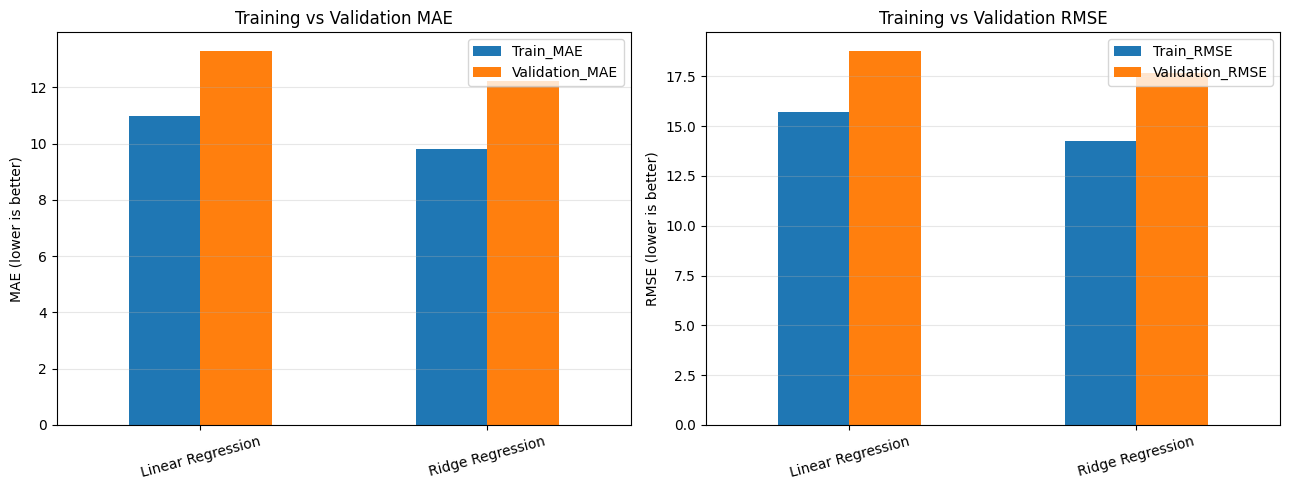

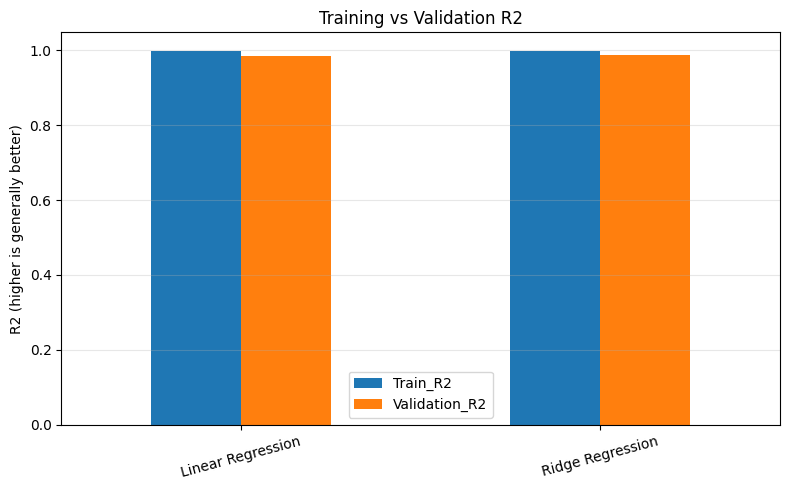

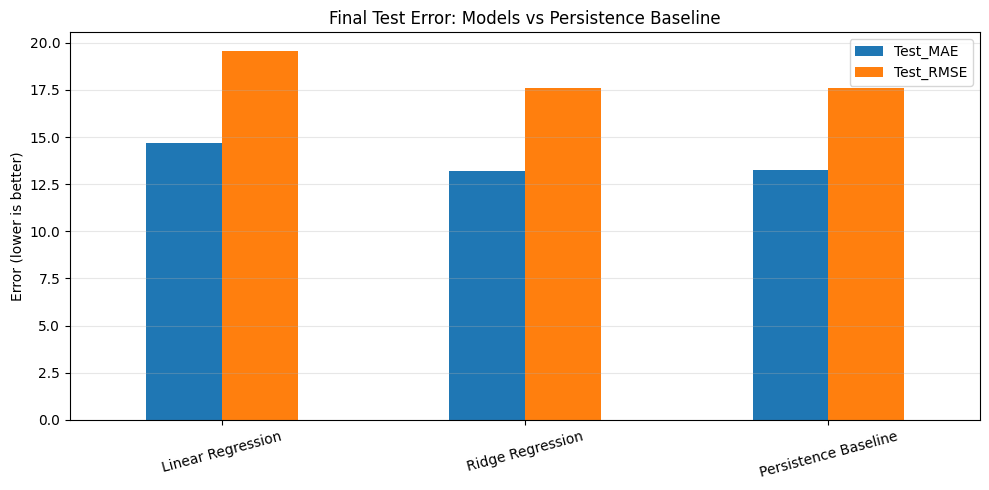

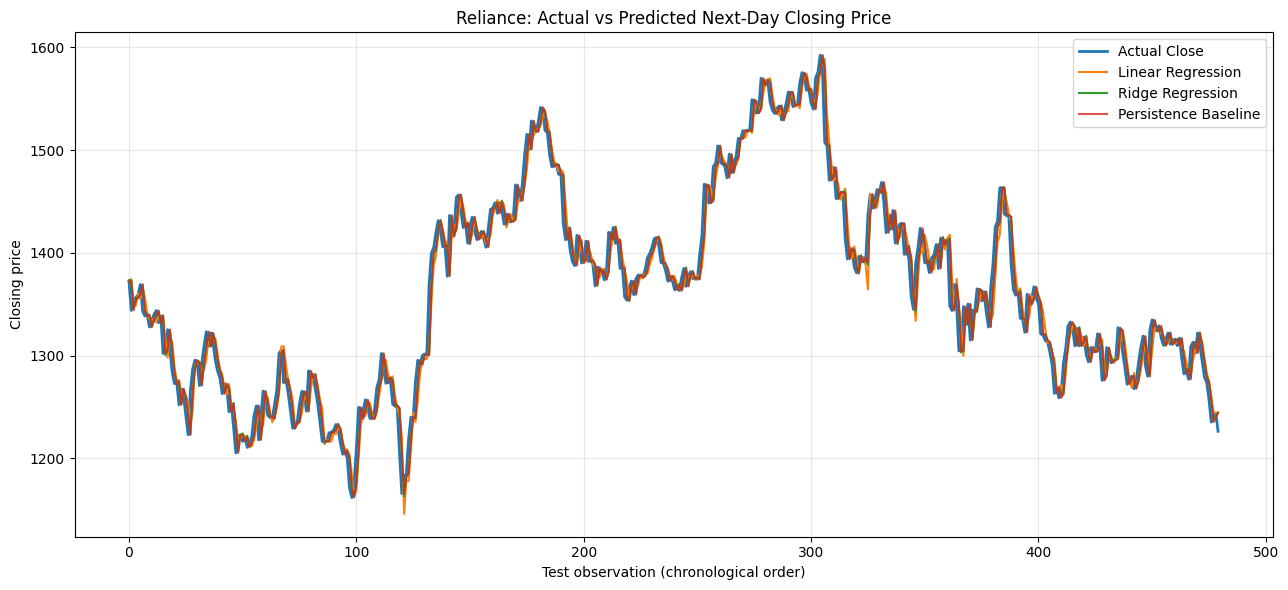

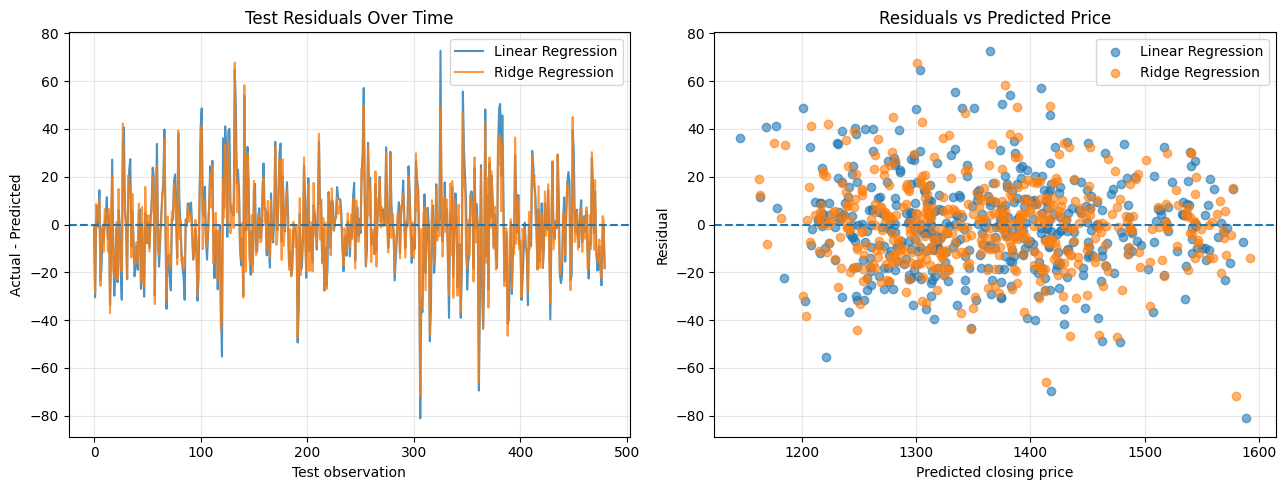


FINAL OUTPUTS SAVED
Output folder:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\final_overfitting_analysis

Files created:
 - Actual_vs_Predicted_Test.png
 - Final_Overfitting_Conclusion.txt
 - Final_Test_Error_Comparison.png
 - Final_Test_Metrics.csv
 - Final_Test_Predictions.csv
 - Test_Residual_Analysis.png
 - Training_Validation_Error_Comparison.png
 - Training_Validation_Metrics.csv
 - Training_Validation_R2.png

Final conclusion report:
C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction\data\processed\stock\final_overfitting_analysis\Final_Overfitting_Conclusion.txt


In [12]:
# ================================================================
# FINAL OVERFITTING ANALYSIS
# RELIANCE STOCK PRICE PREDICTION
# Linear Regression vs Ridge Regression vs Persistence Baseline
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------

output_dir = (
    r"C:\Users\Shilpi Chouhan\Desktop\Stock_Price_Prediction"
    r"\data\processed\stock\final_overfitting_analysis"
)

os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------
# 2. VALIDATE AND PREPARE EXISTING DATA
# ------------------------------------------------

X_train = X_train.copy()
X_test = X_test.copy()

y_train_array = np.asarray(y_train).reshape(-1)
y_test_array = np.asarray(y_test).reshape(-1)

if len(X_train) != len(y_train_array):
    raise ValueError("X_train and y_train have different row counts.")

if len(X_test) != len(y_test_array):
    raise ValueError("X_test and y_test have different row counts.")

if not X_train.columns.equals(X_test.columns):
    raise ValueError("Training and test feature columns do not match.")

if "Close" not in X_test.columns:
    raise ValueError(
        "X_test must contain Close for the persistence baseline."
    )

if not np.isfinite(X_train.to_numpy(dtype=float)).all():
    raise ValueError("X_train contains missing or infinite values.")

if not np.isfinite(X_test.to_numpy(dtype=float)).all():
    raise ValueError("X_test contains missing or infinite values.")

if not (
    np.isfinite(y_train_array).all()
    and np.isfinite(y_test_array).all()
):
    raise ValueError("Target data contains missing or infinite values.")

if len(X_train) < 10:
    raise ValueError("Not enough training rows for this analysis.")

if len(X_test) < 2:
    raise ValueError("Not enough test rows for reliable evaluation.")

# ------------------------------------------------
# 3. CHRONOLOGICAL TRAINING-VALIDATION SPLIT
#    First 80% = training
#    Last 20%  = validation
#    Original test set remains untouched
# ------------------------------------------------

split_index = int(len(X_train) * 0.80)

X_fit = X_train.iloc[:split_index]
X_val = X_train.iloc[split_index:]

y_fit = y_train_array[:split_index]
y_val = y_train_array[split_index:]

print("=" * 75)
print("RELIANCE: FINAL OVERFITTING AND REGULARIZATION ANALYSIS")
print("=" * 75)
print(f"Training rows:   {len(X_fit)}")
print(f"Validation rows: {len(X_val)}")
print(f"Final train rows available: {len(X_train)}")
print(f"Untouched test rows: {len(X_test)}")

# ------------------------------------------------
# 4. DEFINE MODELS
#    Ridge alpha = 0.01 from your earlier Step 8
# ------------------------------------------------

def create_models():
    return {
        "Linear Regression": LinearRegression(),
        "Ridge Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=0.01))
        ])
    }

# ------------------------------------------------
# 5. METRICS FUNCTION
# ------------------------------------------------

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    # MAPE, expressed as a percentage
    nonzero = actual != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
        custom_score = 100 - mape
    else:
        mape = np.nan
        custom_score = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_Percent": mape,
        "Custom_100_minus_MAPE": custom_score
    }

# ------------------------------------------------
# 6. TRAINING-VALIDATION EVALUATION
#    This section checks generalization and possible
#    overfitting before final model fitting.
# ------------------------------------------------

validation_models = create_models()
validation_results = []
validation_predictions = {}

for name, model in validation_models.items():

    model.fit(X_fit, y_fit)

    fit_pred = model.predict(X_fit)
    val_pred = model.predict(X_val)

    train_metrics = calculate_metrics(y_fit, fit_pred)
    val_metrics = calculate_metrics(y_val, val_pred)

    validation_predictions[name] = val_pred

    validation_results.append({
        "Model": name,
        **{
            "Train_" + k: v
            for k, v in train_metrics.items()
        },
        **{
            "Validation_" + k: v
            for k, v in val_metrics.items()
        },
        "MAE_Gap": val_metrics["MAE"] - train_metrics["MAE"],
        "RMSE_Gap": val_metrics["RMSE"] - train_metrics["RMSE"],
        "R2_Gap": train_metrics["R2"] - val_metrics["R2"]
    })

validation_df = pd.DataFrame(validation_results)

print("\n" + "=" * 75)
print("A. TRAINING VS VALIDATION RESULTS")
print("=" * 75)
print(validation_df.round(4).to_string(index=False))

validation_df.to_csv(
    os.path.join(output_dir, "Training_Validation_Metrics.csv"),
    index=False
)

# ------------------------------------------------
# 7. FINAL FIT ON ALL TRAINING DATA
#    Evaluate only on the existing held-out test set
# ------------------------------------------------

final_models = create_models()
test_results = []
test_predictions = {}

for name, model in final_models.items():

    model.fit(X_train, y_train_array)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_metrics = calculate_metrics(y_train_array, train_pred)
    test_metrics = calculate_metrics(y_test_array, test_pred)

    test_predictions[name] = test_pred

    test_results.append({
        "Model": name,
        **{
            "Train_" + k: v
            for k, v in train_metrics.items()
        },
        **{
            "Test_" + k: v
            for k, v in test_metrics.items()
        },
        "MAE_Gap": test_metrics["MAE"] - train_metrics["MAE"],
        "RMSE_Gap": test_metrics["RMSE"] - train_metrics["RMSE"],
        "R2_Gap": train_metrics["R2"] - test_metrics["R2"]
    })

# Persistence baseline: tomorrow's close = today's close
baseline_pred = X_test["Close"].to_numpy()

baseline_metrics = calculate_metrics(y_test_array, baseline_pred)

test_results.append({
    "Model": "Persistence Baseline",
    **{
        "Train_" + k: np.nan
        for k in baseline_metrics
    },
    **{
        "Test_" + k: v
        for k, v in baseline_metrics.items()
    },
    "MAE_Gap": np.nan,
    "RMSE_Gap": np.nan,
    "R2_Gap": np.nan
})

test_df = pd.DataFrame(test_results)

print("\n" + "=" * 75)
print("B. FINAL TEST SET RESULTS")
print("=" * 75)
print(test_df.round(4).to_string(index=False))

test_df.to_csv(
    os.path.join(output_dir, "Final_Test_Metrics.csv"),
    index=False
)

# ------------------------------------------------
# 8. AUTOMATIC CONCLUSION ABOUT OVERFITTING
# ------------------------------------------------

linear = validation_df[
    validation_df["Model"] == "Linear Regression"
].iloc[0]

ridge = validation_df[
    validation_df["Model"] == "Ridge Regression"
].iloc[0]

linear_test = test_df[
    test_df["Model"] == "Linear Regression"
].iloc[0]

ridge_test = test_df[
    test_df["Model"] == "Ridge Regression"
].iloc[0]

baseline_test = test_df[
    test_df["Model"] == "Persistence Baseline"
].iloc[0]

print("\n" + "=" * 75)
print("C. AUTOMATIC CONCLUSION")
print("=" * 75)

print("\n1. LINEAR REGRESSION: POSSIBLE OVERFITTING")

print(
    f"Training MAE: {linear['Train_MAE']:.4f} | "
    f"Validation MAE: {linear['Validation_MAE']:.4f}"
)
print(
    f"Training RMSE: {linear['Train_RMSE']:.4f} | "
    f"Validation RMSE: {linear['Validation_RMSE']:.4f}"
)
print(
    f"Training R2: {linear['Train_R2']:.4f} | "
    f"Validation R2: {linear['Validation_R2']:.4f}"
)

if (
    linear["Validation_MAE"] > linear["Train_MAE"]
    and linear["Validation_RMSE"] > linear["Train_RMSE"]
    and linear["Validation_R2"] < linear["Train_R2"]
):
    print(
        "Interpretation: Validation performance is worse than training "
        "performance across all three metrics. This indicates a "
        "generalization gap and possible overfitting, not proof of it."
    )
else:
    print(
        "Interpretation: The metrics do not all show the same "
        "overfitting pattern. Examine the gap sizes and absolute "
        "validation performance."
    )

print("\n2. DID RIDGE IMPROVE VALIDATION PERFORMANCE?")

mae_improvement = (
    (linear["Validation_MAE"] - ridge["Validation_MAE"])
    / linear["Validation_MAE"] * 100
)

rmse_improvement = (
    (linear["Validation_RMSE"] - ridge["Validation_RMSE"])
    / linear["Validation_RMSE"] * 100
)

print(f"Validation MAE improvement: {mae_improvement:.2f}%")
print(f"Validation RMSE improvement: {rmse_improvement:.2f}%")
print(
    f"Linear R2 gap: {linear['R2_Gap']:.4f} | "
    f"Ridge R2 gap: {ridge['R2_Gap']:.4f}"
)
print(
    f"Linear MAE gap: {linear['MAE_Gap']:.4f} | "
    f"Ridge MAE gap: {ridge['MAE_Gap']:.4f}"
)
print(
    f"Linear RMSE gap: {linear['RMSE_Gap']:.4f} | "
    f"Ridge RMSE gap: {ridge['RMSE_Gap']:.4f}"
)

if mae_improvement > 0 and rmse_improvement > 0:
    print(
        "Interpretation: Ridge improved both validation error metrics. "
        "This supports better predictive generalization on this split."
    )
else:
    print(
        "Interpretation: Ridge did not improve both validation errors. "
        "Regularization has not demonstrated a consistent improvement."
    )

if (
    ridge["MAE_Gap"] < linear["MAE_Gap"]
    and ridge["RMSE_Gap"] < linear["RMSE_Gap"]
    and ridge["R2_Gap"] < linear["R2_Gap"]
):
    print(
        "All three signed generalization gaps are smaller for Ridge."
    )
else:
    print(
        "Not all generalization gaps are smaller for Ridge. "
        "Do not claim that every aspect of overfitting was reduced."
    )

print("\n3. UNTOUCHED TEST SET AND BASELINE")

print(
    f"Linear Regression: MAE={linear_test['Test_MAE']:.4f}, "
    f"RMSE={linear_test['Test_RMSE']:.4f}, "
    f"R2={linear_test['Test_R2']:.4f}"
)
print(
    f"Ridge Regression:  MAE={ridge_test['Test_MAE']:.4f}, "
    f"RMSE={ridge_test['Test_RMSE']:.4f}, "
    f"R2={ridge_test['Test_R2']:.4f}"
)
print(
    f"Persistence:       MAE={baseline_test['Test_MAE']:.4f}, "
    f"RMSE={baseline_test['Test_RMSE']:.4f}, "
    f"R2={baseline_test['Test_R2']:.4f}"
)

if (
    ridge_test["Test_MAE"] < baseline_test["Test_MAE"]
    and ridge_test["Test_RMSE"] < baseline_test["Test_RMSE"]
):
    print(
        "Ridge outperformed the persistence baseline on test MAE "
        "and RMSE. This supports adding predictive value on this test set."
    )
else:
    print(
        "Ridge did not outperform the persistence baseline on both "
        "test MAE and RMSE. Do not select Ridge solely because it "
        "outperformed Linear Regression."
    )

if (
    ridge_test["Test_MAE"] < linear_test["Test_MAE"]
    and ridge_test["Test_RMSE"] < linear_test["Test_RMSE"]
):
    print(
        "Ridge also outperformed Linear Regression on both test "
        "error metrics."
    )
else:
    print(
        "Ridge did not improve both test error metrics over "
        "Linear Regression."
    )

print(
    "\nMetric note: MAPE is percentage error. The custom "
    "100 - MAPE score is not standard classification accuracy. "
    "R2 is not classification accuracy either."
)

# ------------------------------------------------
# 9. PLOT: TRAINING VS VALIDATION ERRORS
# ------------------------------------------------

plot_df = validation_df.set_index("Model")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_df[
    ["Train_MAE", "Validation_MAE"]
].plot(kind="bar", ax=axes[0])

axes[0].set_title("Training vs Validation MAE")
axes[0].set_ylabel("MAE (lower is better)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", alpha=0.3)

plot_df[
    ["Train_RMSE", "Validation_RMSE"]
].plot(kind="bar", ax=axes[1])

axes[1].set_title("Training vs Validation RMSE")
axes[1].set_ylabel("RMSE (lower is better)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "Training_Validation_Error_Comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 10. PLOT: TRAINING VS VALIDATION R2
# ------------------------------------------------

plot_df[
    ["Train_R2", "Validation_R2"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Training vs Validation R2")
plt.ylabel("R2 (higher is generally better)")
plt.xlabel("")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "Training_Validation_R2.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 11. PLOT: FINAL TEST METRICS INCLUDING BASELINE
# ------------------------------------------------

test_plot = test_df.set_index("Model")

test_plot[
    ["Test_MAE", "Test_RMSE"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Final Test Error: Models vs Persistence Baseline")
plt.ylabel("Error (lower is better)")
plt.xlabel("")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "Final_Test_Error_Comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 12. PLOT: ACTUAL VS PREDICTED TEST PRICES
# ------------------------------------------------

plt.figure(figsize=(13, 6))
plt.plot(y_test_array, label="Actual Close", linewidth=2)
plt.plot(
    test_predictions["Linear Regression"],
    label="Linear Regression"
)
plt.plot(
    test_predictions["Ridge Regression"],
    label="Ridge Regression"
)
plt.plot(
    baseline_pred,
    label="Persistence Baseline",
    alpha=0.8
)

plt.title("Reliance: Actual vs Predicted Next-Day Closing Price")
plt.xlabel("Test observation (chronological order)")
plt.ylabel("Closing price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "Actual_vs_Predicted_Test.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 13. PLOT: TEST RESIDUALS
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, pred in test_predictions.items():
    residuals = y_test_array - pred
    axes[0].plot(residuals, label=name, alpha=0.8)

axes[0].axhline(0, linestyle="--")
axes[0].set_title("Test Residuals Over Time")
axes[0].set_xlabel("Test observation")
axes[0].set_ylabel("Actual - Predicted")
axes[0].legend()
axes[0].grid(alpha=0.3)

for name, pred in test_predictions.items():
    residuals = y_test_array - pred
    axes[1].scatter(
        pred, residuals, label=name, alpha=0.6
    )

axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs Predicted Price")
axes[1].set_xlabel("Predicted closing price")
axes[1].set_ylabel("Residual")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "Test_Residual_Analysis.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 14. SAVE TEST PREDICTIONS
# ------------------------------------------------

prediction_df = pd.DataFrame({
    "Actual_Next_Day_Close": y_test_array,
    "Linear_Regression_Prediction":
        test_predictions["Linear Regression"],
    "Ridge_Regression_Prediction":
        test_predictions["Ridge Regression"],
    "Persistence_Baseline_Prediction": baseline_pred
})

prediction_df["Linear_Residual"] = (
    prediction_df["Actual_Next_Day_Close"]
    - prediction_df["Linear_Regression_Prediction"]
)

prediction_df["Ridge_Residual"] = (
    prediction_df["Actual_Next_Day_Close"]
    - prediction_df["Ridge_Regression_Prediction"]
)

prediction_df.to_csv(
    os.path.join(output_dir, "Final_Test_Predictions.csv"),
    index=False
)

# ------------------------------------------------
# 15. FINAL REPORT FILE
# ------------------------------------------------

report_lines = [
    "FINAL CONCLUSION: RELIANCE OVERFITTING ANALYSIS",
    "=" * 60,
    "",
    "Linear Regression is assessed using chronological training "
    "and validation data.",
    f"Linear validation MAE: {linear['Validation_MAE']:.4f}",
    f"Linear validation RMSE: {linear['Validation_RMSE']:.4f}",
    f"Linear validation R2: {linear['Validation_R2']:.4f}",
    f"Linear MAE gap: {linear['MAE_Gap']:.4f}",
    f"Linear RMSE gap: {linear['RMSE_Gap']:.4f}",
    f"Linear R2 gap: {linear['R2_Gap']:.4f}",
    "",
    "Ridge Regression uses StandardScaler and alpha=0.01.",
    f"Ridge validation MAE: {ridge['Validation_MAE']:.4f}",
    f"Ridge validation RMSE: {ridge['Validation_RMSE']:.4f}",
    f"Ridge validation R2: {ridge['Validation_R2']:.4f}",
    f"Ridge MAE gap: {ridge['MAE_Gap']:.4f}",
    f"Ridge RMSE gap: {ridge['RMSE_Gap']:.4f}",
    f"Ridge R2 gap: {ridge['R2_Gap']:.4f}",
    "",
    f"Ridge validation MAE improvement: {mae_improvement:.2f}%",
    f"Ridge validation RMSE improvement: {rmse_improvement:.2f}%",
    "",
    "TEST SET:",
    f"Linear MAE: {linear_test['Test_MAE']:.4f}",
    f"Linear RMSE: {linear_test['Test_RMSE']:.4f}",
    f"Linear R2: {linear_test['Test_R2']:.4f}",
    f"Ridge MAE: {ridge_test['Test_MAE']:.4f}",
    f"Ridge RMSE: {ridge_test['Test_RMSE']:.4f}",
    f"Ridge R2: {ridge_test['Test_R2']:.4f}",
    f"Baseline MAE: {baseline_test['Test_MAE']:.4f}",
    f"Baseline RMSE: {baseline_test['Test_RMSE']:.4f}",
    f"Baseline R2: {baseline_test['Test_R2']:.4f}",
    "",
    "Interpretation: A training-validation gap indicates a difference "
    "in performance, not automatic proof of overfitting. Ridge is "
    "supported if validation and test metrics improve; the untouched "
    "test comparison against the persistence baseline is also essential.",
    "",
    "MAPE is a percentage error. 100 - MAPE is a custom indicator, "
    "not standard classification accuracy."
]

report_path = os.path.join(
    output_dir, "Final_Overfitting_Conclusion.txt"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write("\n".join(report_lines))

print("\n" + "=" * 75)
print("FINAL OUTPUTS SAVED")
print("=" * 75)
print(f"Output folder:\n{output_dir}")
print("\nFiles created:")
for filename in sorted(os.listdir(output_dir)):
    print(" -", filename)

print("\nFinal conclusion report:")
print(report_path)
